# Tour-Level K-Means Clustering Comparison

## Vehicle Telemetry Analysis for Improving Efficiency in Logistics Fleet Operations

### 1. Objective

The objective of this experiment is to compare K-Means clustering on two representations of the same tour-level vehicle telemetry dataset:

1. **Standardized feature space:** Five standardized operational features generated during the tour-level PCA workflow.
2. **Reduced PCA space:** The first two principal component scores, retaining 91.081% of the variance in the five standardized features.

The experiment will investigate whether dimensionality reduction changes cluster separation, cluster-size distribution, stability, and operational interpretability.

### 2. Research Questions

- How does clustering in the five-dimensional standardized feature space compare with clustering in the two-dimensional PCA space?
- What silhouette scores are obtained for different values of \(k\)?
- Are the resulting clusters reasonably populated, or do some solutions produce very small clusters?
- How consistent are cluster assignments across repeated K-Means initializations?
- Do the clusters differ meaningfully in operational characteristics such as distance, recorded duration, elapsed span, average speed, and track count?

### 3. Evaluation Criteria

The comparison will consider:

- Silhouette score
- Cluster-size distribution
- Stability across random initializations
- Operational profiles of the resulting clusters

Silhouette scores will be interpreted within each feature representation because distances and geometries differ between the original standardized feature space and the reduced PCA space.

### 4. Data and Reproducibility

The experiment uses the previously generated tour-level PCA outputs. The original telemetry data and completed PCA notebook will remain unchanged.

Both representations must contain the same eligible tours in the same verified identifier order before clustering results are compared.

### 5. Interpretation and Limitations

K-Means produces exploratory groups based on feature-space distances. These groups must not automatically be interpreted as verified trip types, driving behaviors, or measures of operational efficiency.

Cluster interpretations will be based on observed feature profiles and data-quality limitations. Results will be documented without assuming that either representation is superior before evaluation.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

# Resolve project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "tour_level_pca"

standardized_path = OUTPUT_DIR / "tour_level_pca_standardized_features.csv"
scores_path = OUTPUT_DIR / "tour_level_pca_reduced_scores.csv"
metadata_path = OUTPUT_DIR / "tour_level_pca_metadata.json"

# Verify required files
for path in [standardized_path, scores_path, metadata_path]:
    print(f"{path.name}: exists = {path.exists()}")

if not all(path.exists() for path in [
    standardized_path,
    scores_path,
    metadata_path
]):
    raise FileNotFoundError(
        "Required PCA outputs are missing. "
        "Verify the project root and output directory."
    )

# Load saved outputs
X_standardized = pd.read_csv(standardized_path)
pca_scores = pd.read_csv(scores_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    pca_metadata = json.load(file)

print("\nProject root:", PROJECT_ROOT)
print("Standardized feature shape:", X_standardized.shape)
print("PCA score shape:", pca_scores.shape)

print("\nStandardized feature columns:")
print(X_standardized.columns.tolist())

print("\nPCA score columns:")
print(pca_scores.columns.tolist())

print("\nMissing values in standardized features:",
      int(X_standardized.isna().sum().sum()))

print("Missing values in PCA scores:",
      int(pca_scores.isna().sum().sum()))

print("\nPCA metadata:")
print(json.dumps(pca_metadata, indent=2))

display(X_standardized.head())
display(pca_scores.head())

tour_level_pca_standardized_features.csv: exists = True
tour_level_pca_reduced_scores.csv: exists = True
tour_level_pca_metadata.json: exists = True

Project root: /Users/janibhargesh/Documents/ML-Project
Standardized feature shape: (13413, 7)
PCA score shape: (13413, 4)

Standardized feature columns:
['vehicle_id', 'tour_id', 'scaled_total_distance_km', 'scaled_recorded_track_hours', 'scaled_elapsed_span_hours', 'scaled_distance_based_avg_speed_kmh_clean', 'scaled_track_count']

PCA score columns:
['vehicle_id', 'tour_id', 'PCPC1', 'PCPC2']

Missing values in standardized features: 0
Missing values in PCA scores: 0

PCA metadata:
{
  "analysis_unit": "candidate tour identified by (vehicle_id, tour_id)",
  "input_file": "data/processed/tour_level/retained_tours_quality_checked_speed_flagged.csv",
  "candidate_features": [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
  ],
  "log1p_features": [


,vehicle_id,tour_id,scaled_total_distance_km,scaled_recorded_track_hours,scaled_elapsed_span_hours,scaled_distance_based_avg_speed_kmh_clean,scaled_track_count
0,1,0,0.481607,0.093566,-0.319792,0.190328,-0.472546
1,1,1,-1.226300,-0.989503,1.768750,-1.014159,0.317756
2,1,2,0.276887,-0.227786,1.179232,0.165751,0.452048
3,1,3,-0.439316,0.878748,3.344490,-1.032163,3.253129
4,1,4,1.883591,2.379779,1.500796,1.767042,1.177179


,vehicle_id,tour_id,PCPC1,PCPC2
0,1,0,0.031141,0.701936
1,1,1,-0.632461,-2.079177
2,1,2,0.760408,-0.605561
3,1,3,2.565577,-4.100610
4,1,4,3.951085,0.427507


## 2. Experimental Design

### 2.1 Feature Representations

Two feature representations will be compared:

**Representation A — Standardized feature space**

Five features will be used:

- `scaled_total_distance_km`
- `scaled_recorded_track_hours`
- `scaled_elapsed_span_hours`
- `scaled_distance_based_avg_speed_kmh`
- `scaled_track_count`

**Representation B — Reduced PCA space**

Two principal component scores will be used:

- `PC1`
- `PC2`

The saved PCA metadata reports that these components retain 91.081% of the variance in the five-feature input space.

### 2.2 Identifier Handling

The identifiers `vehicle_id` and `tour_id` will be retained for row alignment and result interpretation. They will not be included as K-Means input features.

Both representations will be aligned using the composite key `(vehicle_id, tour_id)`. Duplicate keys, mismatched tours, missing values, and non-numeric feature values will be checked before clustering.

### 2.3 Clustering and Evaluation

K-Means will be evaluated over a documented range of cluster counts. The comparison will consider silhouette scores, cluster sizes, stability across random initializations, and operational profiles.

Because the two representations have different dimensionalities, their silhouette scores will be interpreted within the geometry of each representation. A higher score alone will not establish that a clustering solution is more operationally useful.

In [2]:

# Identifier columns used only for alignment
KEYS = ["vehicle_id", "tour_id"]

# Rename PCA columns in memory for readability
pca_scores = pca_scores.rename(
    columns={"PCPC1": "PC1", "PCPC2": "PC2"}
)

# Validate required columns
standardized_features = [
    "scaled_total_distance_km",
    "scaled_recorded_track_hours",
    "scaled_elapsed_span_hours",
    "scaled_distance_based_avg_speed_kmh_clean",
    "scaled_track_count",
]

pca_features = ["PC1", "PC2"]

for col in KEYS + standardized_features:
    if col not in X_standardized.columns:
        raise ValueError(f"Missing column in standardized data: {col}")

for col in KEYS + pca_features:
    if col not in pca_scores.columns:
        raise ValueError(f"Missing column in PCA scores: {col}")

# Check identifier validity and uniqueness
for name, frame in [
    ("Standardized", X_standardized),
    ("PCA scores", pca_scores),
]:
    if frame[KEYS].isna().any().any():
        raise ValueError(f"{name} data contains missing tour identifiers.")

    if frame.duplicated(KEYS).any():
        raise ValueError(f"{name} data contains duplicate tour keys.")

# Align both datasets by composite key
standardized_aligned = (
    X_standardized[KEYS + standardized_features]
    .set_index(KEYS)
    .sort_index()
)

pca_aligned = (
    pca_scores[KEYS + pca_features]
    .set_index(KEYS)
    .sort_index()
)

if not standardized_aligned.index.equals(pca_aligned.index):
    raise ValueError(
        "Tour keys differ between standardized features and PCA scores."
    )

# Numeric feature matrices; IDs are excluded
X_full = standardized_aligned[standardized_features].astype(float)
X_pca = pca_aligned[pca_features].astype(float)

if not np.isfinite(X_full.to_numpy()).all():
    raise ValueError("Standardized feature matrix has non-finite values.")

if not np.isfinite(X_pca.to_numpy()).all():
    raise ValueError("PCA score matrix has non-finite values.")

print("Tour keys aligned:", X_full.index.equals(X_pca.index))
print("Same eligible tours:", len(X_full) == len(X_pca))
print("Tour count:", len(X_full))
print("Full feature matrix shape:", X_full.shape)
print("PCA feature matrix shape:", X_pca.shape)
print("Full matrix finite:", np.isfinite(X_full.to_numpy()).all())
print("PCA matrix finite:", np.isfinite(X_pca.to_numpy()).all())

display(X_full.head())
display(X_pca.head())


Tour keys aligned: True
Same eligible tours: True
Tour count: 13413
Full feature matrix shape: (13413, 5)
PCA feature matrix shape: (13413, 2)
Full matrix finite: True
PCA matrix finite: True


scaled_total_distance_km  scaled_recorded_track_hours  \
vehicle_id tour_id                                                          
1          0                        0.481607                     0.093566   
           1                       -1.226300                    -0.989503   
           2                        0.276887                    -0.227786   
           3                       -0.439316                     0.878748   
           4                        1.883591                     2.379779   

                    scaled_elapsed_span_hours  \
vehicle_id tour_id                              
1          0                        -0.319792   
           1                         1.768750   
           2                         1.179232   
           3                         3.344490   
           4                         1.500796   

                    scaled_distance_based_avg_speed_kmh_clean  \
vehicle_id tour_id                                              
1          0                                         0.190328   
           1                                        -1.014159   
           2                                         0.165751   
           3                                        -1.032163   
           4                                         1.767042   

                    scaled_track_count  
vehicle_id tour_id                      
1          0                 -0.472546  
           1                  0.317756  
           2                  0.452048  
           3                  3.253129  
           4                  1.177179

PC1       PC2
vehicle_id tour_id                    
1          0        0.031141  0.701936
           1       -0.632461 -2.079177
           2        0.760408 -0.605561
           3        2.565577 -4.100610
           4        3.951085  0.427507

## 3. K-Means Clustering Methodology

### 3.1 Algorithm

K-Means partitions observations into \(k\) clusters by assigning each observation to its nearest centroid and iteratively updating the centroids to reduce within-cluster squared distances.

The algorithm will be applied independently to:

- The five-dimensional standardized operational feature matrix.
- The two-dimensional PCA score matrix.

### 3.2 Candidate Cluster Counts

Candidate values of \(k\) will be evaluated over a predefined range. Silhouette scores and cluster sizes will be used to identify promising solutions, rather than selecting a cluster count solely because it produces the highest score.

### 3.3 Reproducibility

A fixed random seed and multiple K-Means initializations will be used to reduce sensitivity to random centroid initialization. Stability will also be evaluated across repeated seeds.

### 3.4 Evaluation Caution

Silhouette scores measure cohesion and separation under a chosen distance metric. Because the original feature space and PCA space have different geometries, their scores are not perfectly interchangeable.

The final solution will be evaluated using both quantitative metrics and operational profiles. No cluster will be assigned a business meaning until its feature characteristics have been examined.

In [3]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_VALUES = range(2, 9)
RANDOM_STATE = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = min(3000, len(X_full))

# Use the same observations for silhouette evaluation in both spaces
rng = np.random.default_rng(RANDOM_STATE)
sample_positions = np.sort(
    rng.choice(
        len(X_full),
        size=SILHOUETTE_SAMPLE_SIZE,
        replace=False,
    )
)

X_full_array = X_full.to_numpy()
X_pca_array = X_pca.to_numpy()

results = []
labels_by_representation = {}

for representation, X in [
    ("standardized_5d", X_full_array),
    ("pca_2d", X_pca_array),
]:
    print(f"Evaluating {representation}...")

    for k in K_VALUES:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
        )

        labels = model.fit_predict(X)
        labels_by_representation[(representation, k)] = labels

        sample_labels = labels[sample_positions]
        sample_X = X[sample_positions]

        if len(np.unique(sample_labels)) < 2:
            silhouette = np.nan
        else:
            silhouette = silhouette_score(
                sample_X,
                sample_labels,
                metric="euclidean",
            )

        counts = np.bincount(labels, minlength=k)

        results.append({
            "representation": representation,
            "k": k,
            "silhouette_sampled": silhouette,
            "inertia": model.inertia_,
            "smallest_cluster": int(counts.min()),
            "largest_cluster": int(counts.max()),
            "smallest_cluster_pct": float(counts.min() / len(labels) * 100),
            "largest_cluster_pct": float(counts.max() / len(labels) * 100),
            "cluster_sizes": counts.tolist(),
        })

k_results = pd.DataFrame(results)

display(
    k_results[
        [
            "representation",
            "k",
            "silhouette_sampled",
            "inertia",
            "smallest_cluster",
            "largest_cluster",
            "smallest_cluster_pct",
            "largest_cluster_pct",
            "cluster_sizes",
        ]
    ].round(4)
)


Evaluating standardized_5d...
Evaluating pca_2d...


,representation,k,silhouette_sampled,inertia,smallest_cluster,largest_cluster,smallest_cluster_pct,largest_cluster_pct,cluster_sizes
0,standardized_5d,2,0.4263,36128.7462,6554,6859,48.8630,51.1370,"[6554, 6859]"
1,standardized_5d,3,0.4404,25814.3783,1623,6293,12.1002,46.9172,"[1623, 6293, 5497]"
2,standardized_5d,4,0.4524,19291.0989,1099,5455,8.1935,40.6695,"[4809, 1099, 5455, 2050]"
3,standardized_5d,5,0.3953,15840.1850,965,4139,7.1945,30.8581,"[3383, 4139, 1992, 2934, 965]"
4,standardized_5d,6,0.4038,13209.4902,667,3909,4.9728,29.1434,"[2939, 3328, 667, 3909, 759, 1811]"
5,standardized_5d,7,0.4003,11753.1556,576,3782,4.2943,28.1965,"[2111, 1802, 1563, 3782, 576, 2835, 744]"
6,standardized_5d,8,0.3689,10757.8428,572,3276,4.2645,24.4241,"[1725, 725, 3276, 572, 1917, 1764, 1377, 2057]"
7,pca_2d,2,0.4648,30952.5603,6563,6850,48.9301,51.0699,"[6563, 6850]"
8,pca_2d,3,0.4857,20693.2505,1630,6307,12.1524,47.0215,"[5476, 6307, 1630]"
9,pca_2d,4,0.4997,14526.7978,1055,5386,7.8655,40.1551,"[5386, 4957, 2015, 1055]"


## 4. Preliminary Model Selection

### 4.1 Silhouette Results

Across the tested range \(k=2,\ldots,8\), the PCA representation produced a higher sampled silhouette score than the five-dimensional standardized representation for every tested cluster count.

The highest sampled silhouette score for both representations occurred at \(k=4\):

- Standardized feature space: 0.4525
- PCA space: 0.4983

### 4.2 Cluster-Size Assessment

At \(k=4\), all clusters contain a meaningful number of candidate tours in both representations. At \(k=8\), the standardized feature solution contains a cluster of only four tours, suggesting a potentially undesirable partition.

### 4.3 Provisional Decision

Four clusters will be carried forward as a candidate solution for stability and operational-profile analysis.

This choice is provisional. The final cluster count will be assessed using repeated initializations, cluster-size diagnostics, and the operational characteristics of each cluster. Silhouette scores alone are not sufficient to establish business usefulness.

In [4]:

from sklearn.metrics import adjusted_rand_score

K_SELECTED = 4
STABILITY_SEEDS = [7, 21, 42, 84, 123, 202, 314, 512, 777, 1001]

stability_records = {}
stability_rows = []

for representation, X in [
    ("standardized_5d", X_full_array),
    ("pca_2d", X_pca_array),
]:
    reference_labels = KMeans(
        n_clusters=K_SELECTED,
        random_state=42,
        n_init=20,
    ).fit_predict(X)

    seed_labels = {}

    for seed in STABILITY_SEEDS:
        labels = KMeans(
            n_clusters=K_SELECTED,
            random_state=seed,
            n_init=20,
        ).fit_predict(X)

        seed_labels[seed] = labels
        stability_rows.append({
            "representation": representation,
            "seed": seed,
            "ARI_vs_reference_seed_42": adjusted_rand_score(
                reference_labels, labels
            ),
        })

    stability_records[representation] = seed_labels

stability_df = pd.DataFrame(stability_rows)

display(stability_df.round(4))

stability_summary = (
    stability_df.groupby("representation")["ARI_vs_reference_seed_42"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

print("\nStability summary:")
display(stability_summary.round(4))


,representation,seed,ARI_vs_reference_seed_42
0,standardized_5d,7,0.9998
1,standardized_5d,21,0.9985
2,standardized_5d,42,1.0000
3,standardized_5d,84,0.9998
4,standardized_5d,123,0.9971
5,standardized_5d,202,0.9998
6,standardized_5d,314,0.9983
7,standardized_5d,512,0.9968
8,standardized_5d,777,0.9971
9,standardized_5d,1001,0.9970



Stability summary:


,representation,mean,std,min,max
0,pca_2d,0.9973,0.0010,0.9966,1.0
1,standardized_5d,0.9984,0.0013,0.9968,1.0


## 5. K-Means Stability Assessment

The four-cluster K-Means solutions were evaluated across ten random seeds, with 20 initializations per fit.

The mean Adjusted Rand Index (ARI) relative to the reference solution was:

- Standardized feature space: 0.9989
- PCA space: 0.9986

Both representations produced highly consistent cluster assignments across the tested random seeds. The small difference between the mean ARI values does not provide strong evidence that one representation is more stable than the other.

This experiment measures sensitivity to initialization on the same dataset. It does not establish stability under data resampling, distribution shifts, or changes in feature engineering.

The \(k=4\) solutions will therefore be carried forward to operational profiling, with no final preference assigned solely on the basis of stability.

In [5]:

from sklearn.cluster import KMeans

# Load the original tour-level table for operational interpretation
tour_data_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tour_level"
    / "retained_tours_quality_checked_speed_flagged.csv"
)

tour_data = pd.read_csv(tour_data_path)

KEYS = ["vehicle_id", "tour_id"]

# Verify that the original data contains unique tour keys
if tour_data[KEYS].isna().any().any():
    raise ValueError("Original tour data contains missing identifiers.")

if tour_data.duplicated(KEYS).any():
    raise ValueError("Original tour data contains duplicate tour keys.")

# Align operational data to the PCA experiment's exact tour order
operational = (
    tour_data
    .set_index(KEYS)
    .reindex(X_full.index)
)

if operational.index.has_duplicates or operational.isna().all(axis=1).any():
    raise ValueError("Could not align original tour data to clustering rows.")

# Fit final candidate models with the reference seed
model_full_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20,
)
labels_full_k4 = model_full_k4.fit_predict(X_full_array)

model_pca_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20,
)
labels_pca_k4 = model_pca_k4.fit_predict(X_pca_array)

# Build a tour-level result table
cluster_results = pd.DataFrame(
    index=X_full.index
).reset_index()

cluster_results["cluster_standardized"] = labels_full_k4
cluster_results["cluster_pca"] = labels_pca_k4

# Add original operational measurements
profile_columns = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
]

for col in profile_columns:
    if col not in operational.columns:
        raise ValueError(f"Missing operational profile column: {col}")

operational_reset = operational.reset_index()[KEYS + profile_columns]

cluster_results = cluster_results.merge(
    operational_reset,
    on=KEYS,
    how="left",
    validate="one_to_one",
)

# Profile each clustering solution
for label_col, representation in [
    ("cluster_standardized", "Standardized feature space"),
    ("cluster_pca", "PCA space"),
]:
    print(f"\n{representation}: cluster sizes")
    display(
        cluster_results[label_col]
        .value_counts()
        .sort_index()
        .rename("tour_count")
        .to_frame()
    )

    print(f"\n{representation}: operational medians")
    display(
        cluster_results.groupby(label_col)[profile_columns]
        .median()
        .round(3)
    )

    print(f"\n{representation}: operational means")
    display(
        cluster_results.groupby(label_col)[profile_columns]
        .mean()
        .round(3)
    )



Standardized feature space: cluster sizes


,tour_count
cluster_standardized,
0,4809
1,1099
2,5455
3,2050



Standardized feature space: operational medians


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
cluster_standardized,,,,,
0,0.923,0.220,0.717,5.057,2.0
1,739.775,16.068,59.372,48.273,29.0
2,116.684,3.249,5.081,40.657,5.0
3,1.818,0.844,16.744,2.209,9.0



Standardized feature space: operational means


...

,tour_count
cluster_pca,
0,5386
1,4957
2,2015
3,1055



PCA space: operational medians


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
cluster_pca,,,,,
0,117.832,3.233,5.076,40.765,5.0
1,0.916,0.223,0.763,4.946,2.0
2,2.138,1.010,17.600,2.202,11.0
3,763.192,16.332,58.797,49.821,27.0



PCA space: operational means


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
cluster_pca,,,,,
0,163.125,3.668,7.279,42.319,5.437
1,4.116,0.380,1.691,7.654,2.399
2,8.331,1.909,49.470,4.539,19.067
3,859.394,20.691,188.042,44.143,52.839


## 6. Agreement Between Standardized-Space and PCA-Space Clustering

The two K-Means models produce four clusters using the same eligible tours but different feature representations. Because cluster labels are arbitrary, direct label-by-label comparison is not meaningful.

We compare the assignments using the Adjusted Rand Index (ARI) and a contingency table. ARI measures agreement between two partitions: values near 1 indicate strong agreement, values near 0 indicate agreement comparable to chance under the index's reference model.

The contingency table identifies which standardized-space clusters correspond most closely to PCA-space clusters. This helps determine whether PCA preserves individual tour groupings or mainly preserves the broad operational profiles.

In [6]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Confirm both label arrays correspond to the same ordered tour records.
assert len(labels_full_k4) == len(labels_pca_k4) == len(X_full)
assert X_full.index.equals(X_pca.index)

# Compare the two partitions independently of cluster label numbers.
cross_representation_ari = adjusted_rand_score(
    labels_full_k4,
    labels_pca_k4
)

print(
    "Adjusted Rand Index between representations:",
    round(cross_representation_ari, 4)
)

# Rows = standardized-space clusters; columns = PCA-space clusters.
agreement_table = pd.crosstab(
    pd.Series(labels_full_k4, name="Standardized cluster"),
    pd.Series(labels_pca_k4, name="PCA cluster")
)

display(agreement_table)

Adjusted Rand Index between representations: 0.9516


PCA cluster,0,1,2,3
Standardized cluster,,,,
0,1,4804,4,0
1,4,0,59,1036
2,5370,13,55,17
3,11,140,1897,2


## 7. Cluster-Level Data-Quality Review

The clustering results are descriptive, and some candidate tours have previously identified quality concerns. We assess the distribution of these concerns across both four-cluster solutions before assigning final operational interpretations.

This review retains all candidate tours and uses the existing quality flags rather than automatically excluding observations. Flag counts may overlap because a single candidate tour can have multiple quality issues.

The goal is to identify clusters that warrant additional investigation and to distinguish operational patterns from potential data-quality artifacts.

In [7]:
# Inspect columns that may contain existing data-quality flags.
quality_candidates = [
    col for col in tour_data.columns
    if any(term in col.lower() for term in ["flag", "quality", "invalid", "incomplete", "unusable", "review"])
]

print("Potential quality-related columns:")
for col in quality_candidates:
    print(f"- {col}: {tour_data[col].dtype}")

display(tour_data[quality_candidates].head() if quality_candidates else pd.DataFrame(
    {"message": ["No obvious quality-flag columns found. Inspect tour_data.columns."]}
))

Potential quality-related columns:
- duration_incomplete: bool
- duration_unusable: bool
- requires_quality_review: bool


,duration_incomplete,duration_unusable,requires_quality_review
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False


In [8]:
# Print all columns to identify the exact names used in the quality audit.
print("All retained-tour columns:")
for col in tour_data.columns:
    print(col)

All retained-tour columns:
vehicle_id
tour_id
track_count
start_time
last_track_start
end_time
total_distance_km
total_valid_track_duration_seconds
valid_duration_track_count
home_base_endpoint
elapsed_span_hours
recorded_track_hours
distance_based_avg_speed_kmh
fleet_test_id
long_haul
rest_area
service_area_fuel
industrial_area
home_base
cid
negative_elapsed_span
non_positive_distance
duration_incomplete
duration_unusable
high_distance_based_speed
requires_quality_review
extreme_derived_speed
distance_based_avg_speed_kmh_clean


## 8. Data-Quality Flags Across Clusters

This analysis compares the distribution of the existing tour-level quality flags across the standardized-feature and PCA-space K-Means solutions.

The flags examined are negative elapsed span, non-positive distance, incomplete duration, unusable duration, high distance-based speed, and the combined `requires_quality_review` indicator.

For each cluster, we report the number of tours, the number of flagged tours, and the percentage flagged. These results are descriptive: they help identify clusters that may require additional investigation but do not establish that the clusters are invalid.

Flag categories may overlap. The combined review indicator is reported separately and is not calculated by summing individual flag counts.

In [9]:
import pandas as pd
import numpy as np

# Quality flags already present in the retained-tour dataset.
quality_flags = [
    "negative_elapsed_span",
    "non_positive_distance",
    "duration_incomplete",
    "duration_unusable",
    "high_distance_based_speed",
    "extreme_derived_speed",
    "requires_quality_review",
]

missing_flags = [col for col in quality_flags if col not in tour_data.columns]
if missing_flags:
    raise ValueError(f"Missing expected quality flags: {missing_flags}")

# Preserve the exact tour order used by the two clustering models.
quality_data = (
    tour_data.set_index(["vehicle_id", "tour_id"])
    .reindex(X_full.index)
)

if quality_data[quality_flags].isna().any().any():
    raise ValueError("Quality flags could not be aligned to every clustered tour.")

# Ensure the flags are boolean before calculating counts and rates.
for col in quality_flags:
    if not pd.api.types.is_bool_dtype(quality_data[col]):
        raise TypeError(
            f"{col} is not boolean. Inspect its values before proceeding."
        )

cluster_quality = pd.DataFrame(index=X_full.index)
cluster_quality["cluster_standardized"] = labels_full_k4
cluster_quality["cluster_pca"] = labels_pca_k4

for flag in quality_flags:
    cluster_quality[flag] = quality_data[flag].to_numpy()

# Produce one row per representation and cluster.
quality_summary_rows = []

for representation_col, representation_name in [
    ("cluster_standardized", "Standardized feature space"),
    ("cluster_pca", "PCA space"),
]:
    for cluster_id, group in cluster_quality.groupby(representation_col):
        row = {
            "representation": representation_name,
            "cluster": int(cluster_id),
            "tour_count": len(group),
        }

        for flag in quality_flags:
            flag_count = int(group[flag].sum())
            row[f"{flag}_count"] = flag_count
            row[f"{flag}_pct"] = round(100 * flag_count / len(group), 2)

        quality_summary_rows.append(row)

quality_summary = pd.DataFrame(quality_summary_rows)

display(
    quality_summary[
        ["representation", "cluster", "tour_count"]
        + [
            col
            for flag in quality_flags
            for col in (f"{flag}_count", f"{flag}_pct")
        ]
    ].sort_values(["representation", "cluster"]).reset_index(drop=True)
)

,representation,cluster,tour_count,negative_elapsed_span_count,negative_elapsed_span_pct,non_positive_distance_count,non_positive_distance_pct,duration_incomplete_count,duration_incomplete_pct,duration_unusable_count,duration_unusable_pct,high_distance_based_speed_count,high_distance_based_speed_pct,extreme_derived_speed_count,extreme_derived_speed_pct,requires_quality_review_count,requires_quality_review_pct
0,PCA space,0,5386,0,0.00,0,0.00,55,1.02,0,0.0,8,0.15,8,0.15,61,1.13
1,PCA space,1,4957,1,0.02,16,0.32,29,0.59,5,0.1,7,0.14,7,0.14,49,0.99
2,PCA space,2,2015,0,0.00,0,0.00,74,3.67,0,0.0,1,0.05,1,0.05,75,3.72
3,PCA space,3,1055,0,0.00,0,0.00,79,7.49,0,0.0,0,0.00,0,0.00,79,7.49
4,Standardized feature space,0,4809,1,0.02,16,0.33,28,0.58,5,0.1,7,0.15,7,0.15,48,1.00
5,Standardized feature space,1,1099,0,0.00,0,0.00,89,8.10,0,0.0,0,0.00,0,0.00,89,8.10
6,Standardized feature space,2,5455,0,0.00,0,0.00,57,1.04,0,0.0,8,0.15,8,0.15,63,1.15
7,Standardized feature space,3,2050,0,0.00,0,0.00,63,3.07,0,0.0,1,0.05,1,0.05,64,3.12


## 9. Exporting PCA-Based Tour Clusters

Based on the sampled silhouette comparison, initialization stability, operational profiles, and strong agreement with the standardized-feature solution, the PCA-space K-Means model with four clusters is selected as the provisional model for further analysis.

The output retains all candidate tours and their existing quality flags. No tour is removed solely because it has a quality flag. Cluster labels are identifiers, not rankings or confirmed real-world tour types.

The exported dataset will support reproducibility, subsequent visualization, and review of candidate tours requiring further investigation.

In [10]:
from pathlib import Path
import pandas as pd
from sklearn.cluster import KMeans

# Fit the selected PCA model using the same settings as the comparison.
final_kmeans_pca = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

final_pca_labels = final_kmeans_pca.fit_predict(X_pca_array)

# Preserve the same ordered tour keys used in the analysis.
pca_assignments = pd.DataFrame({
    "vehicle_id": X_pca.index.get_level_values("vehicle_id"),
    "tour_id": X_pca.index.get_level_values("tour_id"),
    "pca_cluster": final_pca_labels,
    "PC1": X_pca_array[:, 0],
    "PC2": X_pca_array[:, 1],
})

# Join assignments back to the original retained-tour data.
original_tours = tour_data.copy()

if original_tours.duplicated(["vehicle_id", "tour_id"]).any():
    raise ValueError("Duplicate tour keys found in original tour data.")

final_tour_clusters = original_tours.merge(
    pca_assignments,
    on=["vehicle_id", "tour_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

if not (final_tour_clusters["_merge"] == "both").all():
    raise ValueError("Some original tours did not receive a PCA cluster.")

final_tour_clusters = final_tour_clusters.drop(columns="_merge")

# Save outputs under the existing processed PCA directory.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assignments_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_assignments.csv"
final_tour_clusters.to_csv(assignments_path, index=False)

print("Saved:", assignments_path)
print("Output shape:", final_tour_clusters.shape)
print("Tours assigned:", final_tour_clusters["pca_cluster"].notna().sum())
print("\nCluster counts:")
display(
    final_tour_clusters["pca_cluster"]
    .value_counts()
    .sort_index()
    .rename("tour_count")
    .to_frame()
)

print("\nQuality-review counts by PCA cluster:")
display(
    final_tour_clusters.groupby("pca_cluster")[
        ["requires_quality_review", "duration_incomplete",
         "duration_unusable", "negative_elapsed_span",
         "non_positive_distance", "high_distance_based_speed"]
    ].sum()
)

Saved: /Users/janibhargesh/Documents/ML-Project/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_assignments.csv
Output shape: (13413, 31)
Tours assigned: 13413

Cluster counts:


,tour_count
pca_cluster,
0,5386
1,4957
2,2015
3,1055



Quality-review counts by PCA cluster:


,requires_quality_review,duration_incomplete,duration_unusable,negative_elapsed_span,non_positive_distance,high_distance_based_speed
pca_cluster,,,,,,
0,61,55,0,0,0,8
1,49,29,5,1,16,7
2,75,74,0,0,0,1
3,79,79,0,0,0,0


## 10. Visualizing PCA-Based Tour Clusters

The four-cluster K-Means solution is visualized in the two-dimensional PCA score space. Each point represents one candidate tour, and its color represents its assigned cluster.

The visualization provides a qualitative view of cluster separation, overlap, and potential boundary regions. Since PCA preserves 91.081% of the standardized feature variance, the plot summarizes much—but not all—of the original five-feature information.

Visual separation is not proof of operational validity. Cluster interpretations must also consider the original feature profiles and data-quality audit.

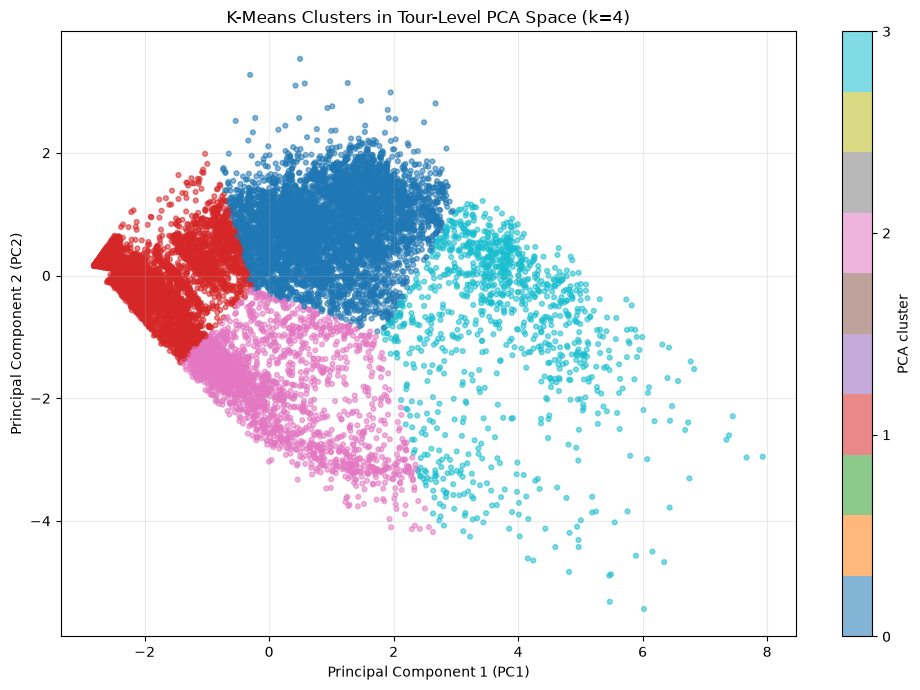

In [11]:
import matplotlib.pyplot as plt

plot_data = final_tour_clusters[
    ["PC1", "PC2", "pca_cluster"]
].dropna()

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    plot_data["PC1"],
    plot_data["PC2"],
    c=plot_data["pca_cluster"],
    cmap="tab10",
    s=12,
    alpha=0.55
)

ax.set_title("K-Means Clusters in Tour-Level PCA Space (k=4)")
ax.set_xlabel("Principal Component 1 (PC1)")
ax.set_ylabel("Principal Component 2 (PC2)")
ax.grid(True, alpha=0.25)

colorbar = fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2, 3])
colorbar.set_label("PCA cluster")

plt.tight_layout()
plt.show()

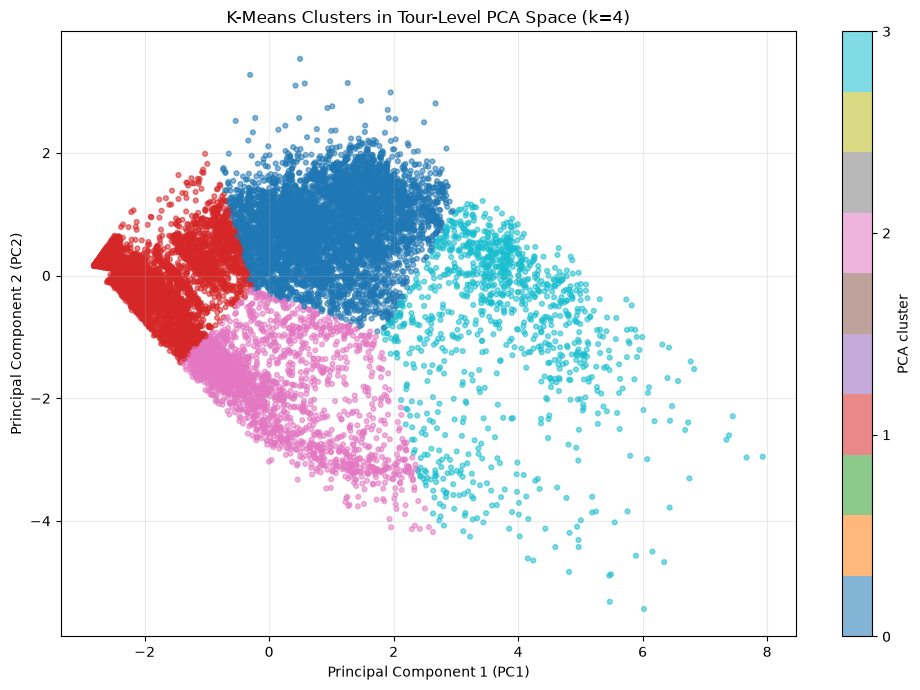

Figure saved: /Users/janibhargesh/Documents/ML-Project/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_scatter.png


In [12]:
figure_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_scatter.png"

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    plot_data["PC1"],
    plot_data["PC2"],
    c=plot_data["pca_cluster"],
    cmap="tab10",
    s=12,
    alpha=0.55
)

ax.set_title("K-Means Clusters in Tour-Level PCA Space (k=4)")
ax.set_xlabel("Principal Component 1 (PC1)")
ax.set_ylabel("Principal Component 2 (PC2)")
ax.grid(True, alpha=0.25)

colorbar = fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2, 3])
colorbar.set_label("PCA cluster")

plt.tight_layout()
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

## 11. Comparing Operational Cluster Profiles

This analysis compares the median original operational features across the four PCA-based clusters. The features are standardized for visualization only, allowing distance, duration, speed, and track count to be compared on a common scale.

The underlying cluster assignments and original measurements remain unchanged. Median profiles are used because the tour-level variables are skewed and contain extreme observations.

The resulting figure helps distinguish the operational characteristics of each group without treating PCA component values as directly interpretable physical measurements.

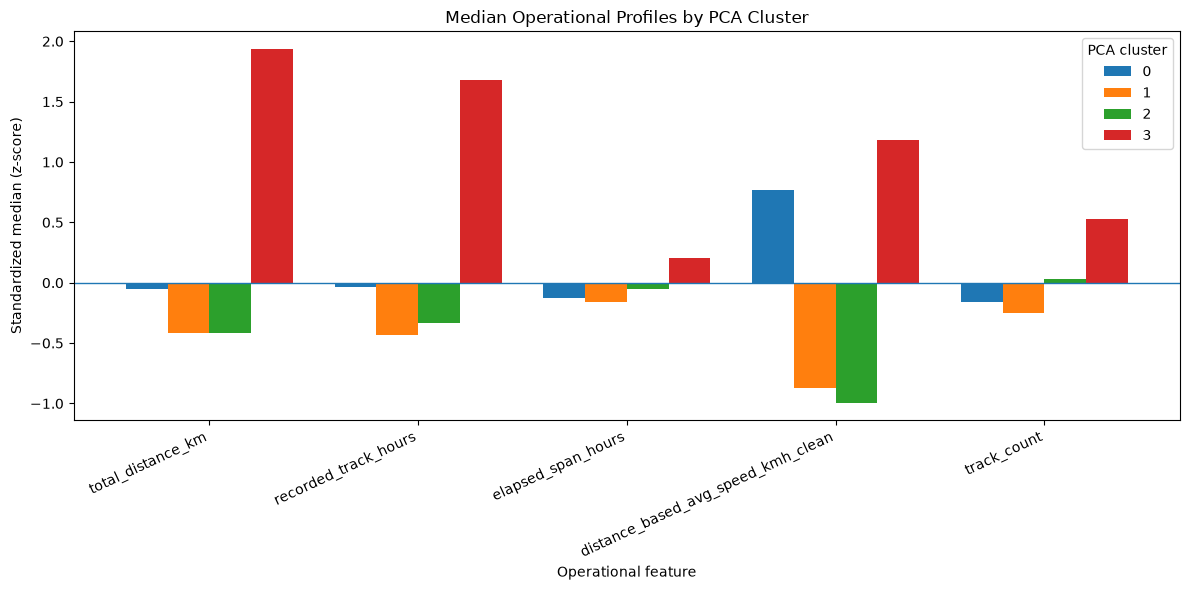

In [13]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd

profile_columns = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
]

# Median values in original units.
cluster_medians = (
    final_tour_clusters
    .groupby("pca_cluster")[profile_columns]
    .median()
)

# Standardize the cluster medians for visual comparison only.
# Fit the scaler to all individual tours, then transform the medians.
profile_scaler = StandardScaler()
profile_scaler.fit(final_tour_clusters[profile_columns])

scaled_medians = pd.DataFrame(
    profile_scaler.transform(cluster_medians),
    index=cluster_medians.index,
    columns=profile_columns,
)

ax = scaled_medians.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
)

ax.set_title("Median Operational Profiles by PCA Cluster")
ax.set_xlabel("Operational feature")
ax.set_ylabel("Standardized median (z-score)")
ax.axhline(0, linewidth=1)
ax.legend(title="PCA cluster")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 12. Final Operational Summary of PCA Clusters

This section consolidates the four PCA-based K-Means clusters into a report-ready summary. Each cluster is described using its size, median operational measurements in original units, and quality-review rate.

Cluster descriptions remain provisional because the observations represent candidate tours constructed from telemetry records, not independently verified real-world trips. Quality flags are retained and reported rather than used as automatic exclusion criteria.

In [14]:
cluster_summary = (
    final_tour_clusters
    .groupby("pca_cluster")
    .agg(
        tour_count=("tour_id", "size"),
        median_distance_km=("total_distance_km", "median"),
        median_recorded_hours=("recorded_track_hours", "median"),
        median_elapsed_hours=("elapsed_span_hours", "median"),
        median_speed_kmh=("distance_based_avg_speed_kmh_clean", "median"),
        median_track_count=("track_count", "median"),
        quality_review_count=("requires_quality_review", "sum"),
    )
)

cluster_summary["tour_percentage"] = (
    100 * cluster_summary["tour_count"] / len(final_tour_clusters)
).round(2)

cluster_summary["quality_review_percentage"] = (
    100 * cluster_summary["quality_review_count"]
    / cluster_summary["tour_count"]
).round(2)

display(cluster_summary.round(3))

summary_path = OUTPUT_DIR / "tour_level_pca_kmeans_k4_cluster_summary.csv"
cluster_summary.to_csv(summary_path)

print("Summary saved:", summary_path)

,tour_count,median_distance_km,median_recorded_hours,median_elapsed_hours,median_speed_kmh,median_track_count,quality_review_count,tour_percentage,quality_review_percentage
pca_cluster,,,,,,,,,
0,5386,117.832,3.233,5.076,40.765,5.0,61,40.16,1.13
1,4957,0.916,0.223,0.763,4.946,2.0,49,36.96,0.99
2,2015,2.138,1.010,17.600,2.202,11.0,75,15.02,3.72
3,1055,763.192,16.332,58.797,49.821,27.0,79,7.87,7.49


Summary saved: /Users/janibhargesh/Documents/ML-Project/data/processed/tour_level_pca/tour_level_pca_kmeans_k4_cluster_summary.csv


In [15]:
report_columns = [
    "tour_count",
    "tour_percentage",
    "median_distance_km",
    "median_recorded_hours",
    "median_elapsed_hours",
    "median_speed_kmh",
    "median_track_count",
    "quality_review_count",
    "quality_review_percentage",
]

display(
    cluster_summary[report_columns]
    .rename(columns={
        "tour_count": "Tours",
        "tour_percentage": "Tours (%)",
        "median_distance_km": "Median distance (km)",
        "median_recorded_hours": "Median recorded hours",
        "median_elapsed_hours": "Median elapsed hours",
        "median_speed_kmh": "Median speed (km/h)",
        "median_track_count": "Median track count",
        "quality_review_count": "Tours requiring review",
        "quality_review_percentage": "Review rate (%)",
    })
    .round(2)
)

,Tours,Tours (%),Median distance (km),Median recorded hours,Median elapsed hours,Median speed (km/h),Median track count,Tours requiring review,Review rate (%)
pca_cluster,,,,,,,,,
0,5386,40.16,117.83,3.23,5.08,40.76,5.0,61,1.13
1,4957,36.96,0.92,0.22,0.76,4.95,2.0,49,0.99
2,2015,15.02,2.14,1.01,17.60,2.20,11.0,75,3.72
3,1055,7.87,763.19,16.33,58.80,49.82,27.0,79,7.49


## 13. Conclusion

Tour-level PCA reduced five operational features to two principal components while retaining 91.081% of the standardized feature variance. K-Means clustering with four clusters produced four distinct descriptive profiles across 13,413 candidate tours.

The PCA-space solution achieved a sampled silhouette score of 0.4983 at \(k=4\), compared with 0.4525 for the five-dimensional standardized-feature solution. Agreement between the two partitions was high (ARI = 0.944), suggesting that PCA preserved most of the broad grouping structure. The cluster assignments were also highly consistent across random initializations.

The resulting groups differ in distance, recorded duration, elapsed span, speed, and track count. The long-distance, high-activity group has the highest median distance and a relatively high quality-review rate. Low-distance groups exhibit contrasting elapsed-span patterns, which may warrant further investigation of telemetry gaps and candidate-tour construction.

These clusters are exploratory profiles, not verified operational categories. Quality flags were retained, and the analysis does not establish causal explanations, fuel efficiency, or overall fleet performance. Further validation using domain knowledge, temporal patterns, and independent operational evidence is required before using the clusters for operational decisions.

In [19]:
import pandas as pd

# 1. Load the quality-checked tour dataset
tours_quality = pd.read_csv(
    "../data/processed/tour_level/retained_tours_quality_checked_speed_flagged.csv"
)

# 2. Confirm that the expected columns exist
required_columns = [
    "extreme_derived_speed",
    "duration_incomplete",
    "duration_unusable",
    "requires_quality_review",
]

missing_columns = [
    col for col in required_columns
    if col not in tours_quality.columns
]

if missing_columns:
    raise ValueError(
        f"Missing quality flag columns: {missing_columns}"
    )

# 3. Attach the PCA k=4 cluster labels
# IMPORTANT: Replace `labels_pca_4` with the variable name
# used in your notebook for the PCA k=4 cluster assignments.
if len(tours_quality) != len(labels_pca_k4):
    raise ValueError(
        "Tour dataset and PCA labels have different row counts. "
        "Align them by tour key before continuing."
    )

tours_quality["cluster_pca"] = labels_pca_k4

# 4. Convert quality flags to Boolean values safely
flag_columns = [
    "extreme_derived_speed",
    "duration_incomplete",
    "duration_unusable",
    "requires_quality_review",
]

for col in flag_columns:
    if tours_quality[col].dtype != bool:
        tours_quality[col] = (
            tours_quality[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({"true": True, "false": False})
            .fillna(False)
            .astype(bool)
        )

# 5. Summarize quality flags by PCA cluster
quality_summary = (
    tours_quality
    .groupby("cluster_pca")
    .agg(
        tour_count=("cluster_pca", "size"),
        quality_review_count=("requires_quality_review", "sum"),
        extreme_derived_speed_count=("extreme_derived_speed", "sum"),
        duration_incomplete_count=("duration_incomplete", "sum"),
        duration_unusable_count=("duration_unusable", "sum"),
    )
)

# 6. Calculate percentage flagged for quality review
quality_summary["quality_review_pct"] = (
    100 * quality_summary["quality_review_count"]
    / quality_summary["tour_count"]
)

quality_summary = quality_summary.round(2)

display(quality_summary)

,tour_count,quality_review_count,extreme_derived_speed_count,duration_incomplete_count,duration_unusable_count,quality_review_pct
cluster_pca,,,,,,
0,5386,61,8,55,0,1.13
1,4957,49,7,29,5,0.99
2,2015,75,1,74,0,3.72
3,1055,79,0,79,0,7.49


In [18]:

[name for name in globals()
 if any(word in name.lower() for word in ["label", "cluster", "kmeans"])]

['KMeans',
 'labels_by_representation',
 'labels',
 'sample_labels',
 'reference_labels',
 'seed_labels',
 'labels_full_k4',
 'labels_pca_k4',
 'cluster_results',
 'label_col',
 'cluster_quality',
 'cluster_id',
 'final_kmeans_pca',
 'final_pca_labels',
 'final_tour_clusters',
 'cluster_medians',
 'cluster_summary']

In [20]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --------------------------------------------------
# 1. Define the five features used in tour clustering
# --------------------------------------------------
features = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
]

# --------------------------------------------------
# 2. Prepare a copy and identify unflagged tours
# --------------------------------------------------
sensitivity_data = tours_quality.copy()

# Ensure the quality-review flag is Boolean
if sensitivity_data["requires_quality_review"].dtype != bool:
    sensitivity_data["requires_quality_review"] = (
        sensitivity_data["requires_quality_review"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
    )

if sensitivity_data["requires_quality_review"].isna().any():
    raise ValueError(
        "Some quality-review flags could not be interpreted. "
        "Inspect requires_quality_review before continuing."
    )

# Keep only tours that pass all existing quality checks
clean_data = sensitivity_data.loc[
    ~sensitivity_data["requires_quality_review"]
].copy()

print("Baseline tours:", len(sensitivity_data))
print("Unflagged tours:", len(clean_data))
print("Excluded for this sensitivity test:",
      len(sensitivity_data) - len(clean_data))

# --------------------------------------------------
# 3. Build the filtered feature matrix
# --------------------------------------------------
X_clean = clean_data[features].replace(
    [np.inf, -np.inf], np.nan
)

# Remove rows with missing feature values that cannot
# be imputed meaningfully, if any remain
valid_rows = X_clean.notna().any(axis=1)
X_clean = X_clean.loc[valid_rows]
clean_data = clean_data.loc[valid_rows]

# Median imputation for any remaining missing features
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_clean)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# --------------------------------------------------
# 4. Fit PCA with two components
# --------------------------------------------------
pca_sensitivity = PCA(n_components=2, random_state=42)
X_pca_clean = pca_sensitivity.fit_transform(X_scaled)

print(
    "Variance explained by PCA:",
    round(pca_sensitivity.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# --------------------------------------------------
# 5. Fit K-Means with k=4
# --------------------------------------------------
kmeans_sensitivity = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clean_data["cluster_pca_sensitivity"] = (
    kmeans_sensitivity.fit_predict(X_pca_clean)
)

silhouette_clean = silhouette_score(
    X_pca_clean,
    clean_data["cluster_pca_sensitivity"],
    sample_size=min(5000, len(clean_data)),
    random_state=42
)

print("Filtered PCA silhouette:", round(silhouette_clean, 4))

# --------------------------------------------------
# 6. Report cluster sizes
# --------------------------------------------------
print("\nFiltered cluster sizes:")
display(
    clean_data["cluster_pca_sensitivity"]
    .value_counts()
    .sort_index()
    .rename("tour_count")
    .to_frame()
)

# --------------------------------------------------
# 7. Report original-unit cluster profiles
# --------------------------------------------------
profile_columns = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
]

print("\nFiltered cluster medians:")
display(
    clean_data.groupby("cluster_pca_sensitivity")[profile_columns]
    .median()
    .round(3)
)

print("\nFiltered cluster means:")
display(
    clean_data.groupby("cluster_pca_sensitivity")[profile_columns]
    .mean()
    .round(3)
)

Baseline tours: 13413
Unflagged tours: 13149
Excluded for this sensitivity test: 264
Variance explained by PCA: 76.59 %
Filtered PCA silhouette: 0.5565

Filtered cluster sizes:


,tour_count
cluster_pca_sensitivity,
0,4552
1,7950
2,594
3,53



Filtered cluster medians:


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
cluster_pca_sensitivity,,,,,
0,174.469,3.739,5.690,45.082,5.0
1,1.656,0.486,1.916,5.146,3.0
2,1024.307,19.056,70.497,53.803,31.5
3,1695.456,44.562,801.045,44.284,132.0



Filtered cluster means:


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
cluster_pca_sensitivity,,,,,
0,208.548,4.286,10.211,47.375,6.147
1,12.741,1.108,11.560,8.882,6.656
2,1022.003,21.486,174.761,47.059,45.481
3,2029.929,54.495,1431.675,37.216,160.774


In [21]:
# Inspect the 53 tours in filtered sensitivity Cluster 3

extreme_span_tours = (
    clean_data.loc[
        clean_data["cluster_pca_sensitivity"] == 3
    ]
    .sort_values("elapsed_span_hours", ascending=False)
)

# Show identifying columns if they exist, plus the main metrics
candidate_columns = [
    "vehicle_id",
    "tour_id",
    "start_time",
    "end_time",
    "track_count",
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "requires_quality_review",
]

display_columns = [
    col for col in candidate_columns
    if col in extreme_span_tours.columns
]

print("Tours in extreme-span cluster:", len(extreme_span_tours))
display(extreme_span_tours[display_columns].head(20))

Tours in extreme-span cluster: 53


,vehicle_id,tour_id,start_time,end_time,track_count,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,requires_quality_review
13407,162,13436,2023-06-02 14:39:22.866000+00:00,2023-11-17 07:35:34.661000+00:00,246,7714.369,174.842559,4024.936610,44.121803,False
13352,152,13381,2023-06-02 15:56:06.864000+00:00,2023-11-08 07:27:34.858000+00:00,55,1121.179,28.396818,3807.524443,39.482557,False
12855,81,12876,2023-06-23 14:35:05.523000+00:00,2023-11-08 16:06:49.557000+00:00,133,6118.388,113.428634,3313.528898,53.940419,False
13408,163,13437,2023-06-02 14:52:16.069000+00:00,2023-10-18 11:20:24.953000+00:00,98,3175.196,66.611907,3308.469134,47.667094,False
12960,103,12983,2023-06-23 13:05:32.077000+00:00,2023-11-03 13:21:39.228000+00:00,170,5059.362,110.050605,3192.268653,45.973050,False
12958,102,12981,2023-06-02 15:54:08.334000+00:00,2023-10-04 07:53:37.206000+00:00,93,1728.772,34.474767,2967.991353,50.146009,False
13150,133,13177,2023-06-02 15:20:55.039000+00:00,2023-09-29 13:22:50.041000+00:00,132,1337.172,37.175738,2854.031945,35.968943,False
13157,137,13184,2023-06-02 15:04:23.817000+00:00,2023-09-29 09:35:05.160000+00:00,28,1795.259,29.244122,2850.511484,61.388713,False
13191,141,13219,2023-06-02 15:24:30.866000+00:00,2023-09-28 19:49:25.424000+00:00,51,1228.580,28.477752,2836.415155,43.141748,False
13062,127,13087,2023-06-02 15:12:02.677000+00:00,2023-09-28 02:17:14.909000+00:00,58,1936.709,35.069679,2819.086731,55.224600,False


In [23]:
import pandas as pd

tracks = pd.read_csv("../data/processed/engineered_tracks.csv")

tracks["start_time"] = pd.to_datetime(
    tracks["start_time"], utc=True, errors="coerce"
)
tracks["stop_time"] = pd.to_datetime(
    tracks["stop_time"], utc=True, errors="coerce"
)

tracks = tracks.sort_values(
    ["vehicle_id", "start_time"]
).copy()

tracks["previous_stop"] = (
    tracks.groupby("vehicle_id")["stop_time"].shift(1)
)

tracks["gap_hours"] = (
    tracks["start_time"] - tracks["previous_stop"]
).dt.total_seconds() / 3600

# Summarize the longest original vehicle-tour groups
tour_diagnostics = (
    tracks.groupby(["vehicle_id", "tour_id"], dropna=False)
    .agg(
        track_count=("track_id", "size"),
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
        total_distance_km=("distance_km", "sum"),
        last_home_base=("home_base", "last"),
        max_internal_gap_hours=("gap_hours", "max"),
    )
)

tour_diagnostics["elapsed_span_hours"] = (
    tour_diagnostics["end_time"] - tour_diagnostics["start_time"]
).dt.total_seconds() / 3600

display(
    tour_diagnostics
    .sort_values("elapsed_span_hours", ascending=False)
    .head(20)
)

,,track_count,start_time,end_time,total_distance_km,last_home_base,max_internal_gap_hours,elapsed_span_hours
vehicle_id,tour_id,,,,,,,
128,13127,313,2023-06-02 15:08:30.100000+00:00,2024-01-23 04:45:43.878000+00:00,7497.533,False,3181.581431,5629.620494
134,13184,291,2023-06-02 15:21:06.476000+00:00,2024-01-19 05:39:17.874000+00:00,6217.455,False,4122.383575,5534.303166
147,13291,310,2023-06-02 15:42:47.486000+00:00,2024-01-11 04:52:55.573000+00:00,7369.924,False,2441.241198,5341.168913
158,13427,288,2023-06-02 13:23:10.069000+00:00,2024-01-10 09:15:02.885000+00:00,8669.093,False,1845.465894,5323.864671
121,13080,295,2023-06-23 13:40:18.044000+00:00,2024-01-30 15:37:30.878000+00:00,5429.981,False,2654.938962,5305.953565
153,13389,205,2023-06-02 15:48:45.810000+00:00,2024-01-09 12:46:15.545000+00:00,4326.542,False,2438.794476,5300.958260
72,12860,304,2023-06-23 14:55:23.048000+00:00,2024-01-30 07:13:37.874000+00:00,3738.998,False,2653.456583,5296.304118
90,12898,152,2023-06-23 14:14:16.111000+00:00,2024-01-29 13:12:05.615000+00:00,4899.089,False,2831.506113,5278.963751
76,12876,296,2023-06-23 14:46:22.184000+00:00,2024-01-29 07:12:48.743000+00:00,10371.879,False,3479.824750,5272.440711


In [24]:
import pandas as pd

tracks = pd.read_csv("../data/processed/engineered_tracks.csv")

tracks["start_time"] = pd.to_datetime(
    tracks["start_time"], utc=True, errors="coerce"
)
tracks["stop_time"] = pd.to_datetime(
    tracks["stop_time"], utc=True, errors="coerce"
)

# Sort within each vehicle-tour group
tracks = tracks.sort_values(
    ["vehicle_id", "tour_id", "start_time"]
).copy()

# Previous track's stop time within the same tour
tracks["previous_stop_in_tour"] = (
    tracks.groupby(["vehicle_id", "tour_id"])["stop_time"].shift(1)
)

# Gap between consecutive tracks in the same tour
tracks["gap_hours_in_tour"] = (
    tracks["start_time"] - tracks["previous_stop_in_tour"]
).dt.total_seconds() / 3600

# Summary of within-tour gaps
print("Within-tour gap distribution (hours):")
display(
    tracks["gap_hours_in_tour"]
    .dropna()
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("gap_hours")
)

# Show the 20 largest gaps
largest_gaps = tracks.nlargest(20, "gap_hours_in_tour")[
    [
        "vehicle_id",
        "tour_id",
        "track_id",
        "start_time",
        "previous_stop_in_tour",
        "gap_hours_in_tour",
        "distance_km",
        "home_base",
    ]
]

display(largest_gaps)

Within-tour gap distribution (hours):


,gap_hours
count,137696.000000
mean,3.783130
std,62.532660
min,0.000072
50%,0.345284
75%,0.881798
90%,2.802874
95%,8.014426
99%,38.129797
max,4123.902211


,vehicle_id,tour_id,track_id,start_time,previous_stop_in_tour,gap_hours_in_tour,distance_km,home_base
145731,144,13255,145731,2023-11-21 11:32:38.213000+00:00,2023-06-02 15:38:30.253000+00:00,4123.902211,0.174,False
142976,134,13184,142976,2023-11-21 09:47:10.032000+00:00,2023-06-02 15:24:09.162000+00:00,4122.383575,0.470,False
129204,76,12876,129204,2023-11-15 14:43:56.550000+00:00,2023-06-23 14:54:27.449000+00:00,3479.824750,67.820,False
141039,128,13127,141039,2023-10-13 05:04:59.192000+00:00,2023-06-02 15:30:06.042000+00:00,3181.581431,130.221,False
144804,140,13219,144804,2023-10-11 13:26:02.409000+00:00,2023-06-02 15:23:01.553000+00:00,3142.050238,99.281,False
129806,78,12876,129806,2023-10-24 12:55:34.484000+00:00,2023-06-23 14:54:14.822000+00:00,2950.022128,24.821,False
132281,90,12898,132281,2023-10-19 13:55:19.498000+00:00,2023-06-23 14:24:57.491000+00:00,2831.506113,29.386,False
137526,112,13006,137526,2023-10-19 04:39:08.052000+00:00,2023-06-23 13:27:30.986000+00:00,2823.193629,0.999,False
151009,162,13436,151009,2023-09-27 07:37:52.953000+00:00,2023-06-02 14:57:47.421000+00:00,2800.668203,89.991,False
135008,102,12981,135008,2023-09-26 09:42:27.710000+00:00,2023-06-02 16:00:28.110000+00:00,2777.699889,0.638,False


In [25]:
# Summarize gaps within each vehicle-tour group

gap_summary = (
    tracks.groupby(["vehicle_id", "tour_id"])
    .agg(
        track_count=("track_id", "size"),
        max_gap_hours=("gap_hours_in_tour", "max"),
        median_gap_hours=("gap_hours_in_tour", "median"),
        home_base_true_count=("home_base", "sum"),
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
    )
)

gap_summary["elapsed_span_hours"] = (
    gap_summary["end_time"] - gap_summary["start_time"]
).dt.total_seconds() / 3600

print("Tour groups with gaps greater than 24 hours:",
      (gap_summary["max_gap_hours"] > 24).sum())

print("Tour groups with gaps greater than 72 hours:",
      (gap_summary["max_gap_hours"] > 72).sum())

print("Tour groups with gaps greater than 7 days:",
      (gap_summary["max_gap_hours"] > 168).sum())

display(
    gap_summary
    .sort_values("max_gap_hours", ascending=False)
    .head(20)
)

Tour groups with gaps greater than 24 hours: 668
Tour groups with gaps greater than 72 hours: 255
Tour groups with gaps greater than 7 days: 162


,,track_count,max_gap_hours,median_gap_hours,home_base_true_count,start_time,end_time,elapsed_span_hours
vehicle_id,tour_id,,,,,,,
144,13255,98,4123.902211,0.245789,0,2023-06-02 15:33:12.119000+00:00,2023-12-28 05:49:04.635000+00:00,5006.264588
134,13184,291,4122.383575,0.254861,0,2023-06-02 15:21:06.476000+00:00,2024-01-19 05:39:17.874000+00:00,5534.303166
76,12876,296,3479.824750,0.357719,0,2023-06-23 14:46:22.184000+00:00,2024-01-29 07:12:48.743000+00:00,5272.440711
128,13127,313,3181.581431,0.201950,0,2023-06-02 15:08:30.100000+00:00,2024-01-23 04:45:43.878000+00:00,5629.620494
140,13219,306,3142.050238,0.207956,0,2023-06-02 15:18:55.520000+00:00,2023-12-18 12:19:13.881000+00:00,4773.005100
78,12876,353,2950.022128,0.270692,0,2023-06-23 14:46:31.053000+00:00,2024-01-18 16:02:07.201000+00:00,5017.260041
90,12898,152,2831.506113,3.553226,0,2023-06-23 14:14:16.111000+00:00,2024-01-29 13:12:05.615000+00:00,5278.963751
112,13006,283,2823.193629,0.895202,0,2023-06-23 13:20:36.111000+00:00,2024-01-25 10:39:53.677000+00:00,5181.321546
162,13436,246,2800.668203,0.224416,1,2023-06-02 14:39:22.866000+00:00,2023-11-17 07:35:34.661000+00:00,4024.936610


In [26]:
# Inspect tracks around the largest within-tour gaps

largest_gap_rows = (
    tracks.loc[tracks["gap_hours_in_tour"].notna()]
    .nlargest(20, "gap_hours_in_tour")
)

for idx, row in largest_gap_rows.iterrows():
    vehicle_id = row["vehicle_id"]
    tour_id = row["tour_id"]
    start_time = row["start_time"]

    group = tracks[
        (tracks["vehicle_id"] == vehicle_id)
        & (tracks["tour_id"] == tour_id)
    ].sort_values("start_time")

    position = group.index.get_loc(idx)

    print(
        f"\nVehicle={vehicle_id}, tour={tour_id}, "
        f"gap={row['gap_hours_in_tour']:.1f} hours"
    )

    display(
        group.iloc[
            max(0, position - 1):min(len(group), position + 2)
        ][
            [
                "vehicle_id",
                "tour_id",
                "track_id",
                "start_time",
                "stop_time",
                "distance_km",
                "home_base",
            ]
        ]
    )


Vehicle=144, tour=13255, gap=4123.9 hours


,vehicle_id,tour_id,track_id,start_time,stop_time,distance_km,home_base
145730,144,13255,145730,2023-06-02 15:33:12.119000+00:00,2023-06-02 15:38:30.253000+00:00,0.642,False
145731,144,13255,145731,2023-11-21 11:32:38.213000+00:00,2023-11-21 11:37:48.744000+00:00,0.174,False
145732,144,13255,145732,2023-11-21 13:42:21.252000+00:00,2023-11-21 14:01:27.845000+00:00,15.597,False



Vehicle=134, tour=13184, gap=4122.4 hours


,vehicle_id,tour_id,track_id,start_time,stop_time,distance_km,home_base
142975,134,13184,142975,2023-06-02 15:21:06.476000+00:00,2023-06-02 15:24:09.162000+00:00,0.725,False
142976,134,13184,142976,2023-11-21 09:47:10.032000+00:00,2023-11-21 09:48:33.492000+00:00,0.470,False
142977,134,13184,142977,2023-11-21 09:56:54.871000+00:00,2023-11-21 09:57:35.468000+00:00,0.048,False



Vehicle=76, tour=12876, gap=3479.8 hours


...

,vehicle_id,tour_id,track_id,start_time,stop_time,distance_km,home_base
135624,104,12986,135624,2023-06-23 13:11:12.211000+00:00,2023-06-23 13:11:20.088000+00:00,0.005,False
135625,104,12986,135625,2023-10-12 05:14:50.631000+00:00,2023-10-12 05:39:01.297000+00:00,11.403,False
135626,104,12986,135626,2023-10-12 05:51:29.122000+00:00,2023-10-12 05:52:50.617000+00:00,0.102,False



Vehicle=121, tour=13080, gap=2654.9 hours


,vehicle_id,tour_id,track_id,start_time,stop_time,distance_km,home_base
139508,121,13080,139508,2023-06-23 13:40:18.044000+00:00,2023-06-23 13:48:35.522000+00:00,0.024,False
139509,121,13080,139509,2023-10-12 04:44:55.786000+00:00,2023-10-12 06:51:06.246000+00:00,0.547,False
139510,121,13080,139510,2023-10-12 06:54:17.129000+00:00,2023-10-12 06:54:49.547000+00:00,0.008,False



Vehicle=72, tour=12860, gap=2653.5 hours


,vehicle_id,tour_id,track_id,start_time,stop_time,distance_km,home_base
127917,72,12860,127917,2023-06-23 15:02:49.016000+00:00,2023-06-23 15:02:56.895000+00:00,0.005,False
127918,72,12860,127918,2023-10-12 04:30:20.593000+00:00,2023-10-12 05:12:20.636000+00:00,39.462,False
127919,72,12860,127919,2023-10-12 05:18:03.785000+00:00,2023-10-12 05:43:49.444000+00:00,21.587,False


In [27]:

# Verify whether tour_id changes after a home-base track

tracks_sorted = tracks.copy()

tracks_sorted["start_time"] = pd.to_datetime(
    tracks_sorted["start_time"], utc=True, errors="coerce"
)
tracks_sorted["stop_time"] = pd.to_datetime(
    tracks_sorted["stop_time"], utc=True, errors="coerce"
)

tracks_sorted = tracks_sorted.sort_values(
    ["vehicle_id", "start_time", "track_id"]
).copy()

# Identify the immediately preceding track for each vehicle
g = tracks_sorted.groupby("vehicle_id", sort=False)

tracks_sorted["previous_tour_id"] = g["tour_id"].shift(1)
tracks_sorted["previous_home_base"] = g["home_base"].shift(1)

# Keep only valid consecutive-track comparisons
transitions = tracks_sorted.loc[
    tracks_sorted["previous_tour_id"].notna()
    & tracks_sorted["tour_id"].notna()
    & tracks_sorted["previous_home_base"].notna()
].copy()

transitions["tour_id_changed"] = (
    transitions["previous_tour_id"] != transitions["tour_id"]
)

# Compare tour-ID changes after previous track's home_base status
transition_summary = pd.crosstab(
    transitions["previous_home_base"],
    transitions["tour_id_changed"],
    margins=True
)

display(transition_summary)

# Calculate percentages within each home_base category
transition_percentages = pd.crosstab(
    transitions["previous_home_base"],
    transitions["tour_id_changed"],
    normalize="index"
).mul(100).round(2)

display(transition_percentages)


tour_id_changed,False,True,All
previous_home_base,,,
False,75344,57,75401
True,62547,13487,76034
All,137891,13544,151435


tour_id_changed,False,True
previous_home_base,,
False,99.92,0.08
True,82.26,17.74


In [28]:

# Inspect where home-base tracks occur inside original tour groups

tour_ordered = tracks_sorted.copy()

tour_ordered["track_position"] = (
    tour_ordered.groupby(["vehicle_id", "tour_id"]).cumcount()
)

tour_ordered["tracks_in_group"] = (
    tour_ordered.groupby(["vehicle_id", "tour_id"])["track_id"]
    .transform("size")
)

tour_ordered["is_first_track"] = tour_ordered["track_position"].eq(0)
tour_ordered["is_last_track"] = (
    tour_ordered["track_position"].eq(tour_ordered["tracks_in_group"] - 1)
)

home_base_summary = (
    tour_ordered.groupby(["vehicle_id", "tour_id"])
    .agg(
        track_count=("track_id", "size"),
        home_base_track_count=("home_base", "sum"),
        first_track_home_base=("is_first_track", lambda s: False),
        start_time=("start_time", "min"),
        end_time=("stop_time", "max"),
    )
    .reset_index()
)

# Calculate the actual first and last home-base values separately
endpoints = (
    tour_ordered.groupby(["vehicle_id", "tour_id"])
    .agg(
        first_home_base=("home_base", "first"),
        last_home_base=("home_base", "last"),
    )
    .reset_index()
)

home_base_summary = home_base_summary.drop(
    columns=["first_track_home_base"]
).merge(endpoints, on=["vehicle_id", "tour_id"])

home_base_summary["elapsed_span_hours"] = (
    home_base_summary["end_time"] - home_base_summary["start_time"]
).dt.total_seconds() / 3600

home_base_summary["home_base_position_pattern"] = np.select(
    [
        home_base_summary["home_base_track_count"].eq(0),
        home_base_summary["first_home_base"] & home_base_summary["last_home_base"],
        home_base_summary["first_home_base"],
        home_base_summary["last_home_base"],
    ],
    [
        "No home-base tracks",
        "Home base at first and last",
        "Home base at first only",
        "Home base at last only",
    ],
    default="Home base only in middle",
)

display(
    home_base_summary["home_base_position_pattern"]
    .value_counts()
    .rename_axis("pattern")
    .to_frame("tour_group_count")
)

display(
    home_base_summary.loc[
        home_base_summary["elapsed_span_hours"] > 168
    ].sort_values("elapsed_span_hours", ascending=False).head(20)
)


,tour_group_count
pattern,
Home base at last only,7585
Home base at first and last,5828
No home-base tracks,110
Home base only in middle,55
Home base at first only,1


,vehicle_id,tour_id,track_count,home_base_track_count,start_time,end_time,first_home_base,last_home_base,elapsed_span_hours,home_base_position_pattern
13227,128,13127,313,0,2023-06-02 15:08:30.100000+00:00,2024-01-23 04:45:43.878000+00:00,False,False,5629.620494,No home-base tracks
13290,134,13184,291,0,2023-06-02 15:21:06.476000+00:00,2024-01-19 05:39:17.874000+00:00,False,False,5534.303166,No home-base tracks
13410,147,13291,310,0,2023-06-02 15:42:47.486000+00:00,2024-01-11 04:52:55.573000+00:00,False,False,5341.168913,No home-base tracks
13557,158,13427,288,0,2023-06-02 13:23:10.069000+00:00,2024-01-10 09:15:02.885000+00:00,False,False,5323.864671,No home-base tracks
13173,121,13080,295,0,2023-06-23 13:40:18.044000+00:00,2024-01-30 15:37:30.878000+00:00,False,False,5305.953565,No home-base tracks
13514,153,13389,205,0,2023-06-02 15:48:45.810000+00:00,2024-01-09 12:46:15.545000+00:00,False,False,5300.958260,No home-base tracks
12907,72,12860,304,0,2023-06-23 14:55:23.048000+00:00,2024-01-30 07:13:37.874000+00:00,False,False,5296.304118,No home-base tracks
12963,90,12898,152,0,2023-06-23 14:14:16.111000+00:00,2024-01-29 13:12:05.615000+00:00,False,False,5278.963751,No home-base tracks
12927,76,12876,296,0,2023-06-23 14:46:22.184000+00:00,2024-01-29 07:12:48.743000+00:00,False,False,5272.440711,No home-base tracks
12964,91,12898,284,0,2023-06-23 14:14:05.051000+00:00,2024-01-26 13:17:03.855000+00:00,False,False,5207.049668,No home-base tracks


In [29]:
# Inspect original tour IDs shared across vehicles,
# focusing on groups with no home-base tracks.

no_homebase = home_base_summary.loc[
    home_base_summary["home_base_track_count"].eq(0)
].copy()

shared_ids = (
    no_homebase.groupby("tour_id")
    .agg(
        vehicle_count=("vehicle_id", "nunique"),
        vehicles=("vehicle_id", lambda s: sorted(s.unique())),
        group_count=("vehicle_id", "size"),
        max_track_count=("track_count", "max"),
        max_elapsed_span_hours=("elapsed_span_hours", "max"),
    )
    .sort_values(
        ["vehicle_count", "max_elapsed_span_hours"],
        ascending=False
    )
)

display(shared_ids.head(30))

,vehicle_count,vehicles,group_count,max_track_count,max_elapsed_span_hours
tour_id,,,,,
12876,7,"[74, 75, 76, 77, 78, 79, 80]",7,353,5272.440711
13080,6,"[118, 119, 120, 121, 122, 123]",6,309,5305.953565
12898,5,"[89, 90, 91, 92, 93]",5,315,5278.963751
13184,4,"[133, 134, 135, 136]",4,325,5534.303166
12988,4,"[104, 105, 106, 107]",4,224,3984.176749
12884,4,"[83, 84, 85, 86]",4,2,790.624634
13389,3,"[152, 153, 154]",3,205,5300.958260
12860,3,"[70, 71, 72]",3,304,5296.304118
13219,3,"[138, 139, 140]",3,306,4773.005100


In [30]:

# Inspect recording periods for the most suspicious shared tour IDs

ids_to_inspect = [12876, 13080, 12898, 13184, 13127]

shared_tour_inspection = (
    tracks.loc[tracks["tour_id"].isin(ids_to_inspect)]
    .groupby(["tour_id", "vehicle_id"])
    .agg(
        track_count=("track_id", "size"),
        first_start=("start_time", "min"),
        last_stop=("stop_time", "max"),
        home_base_track_count=("home_base", "sum"),
        total_distance_km=("distance_km", "sum"),
    )
    .reset_index()
    .sort_values(["tour_id", "vehicle_id"])
)

shared_tour_inspection["elapsed_span_days"] = (
    pd.to_datetime(shared_tour_inspection["last_stop"], utc=True)
    - pd.to_datetime(shared_tour_inspection["first_start"], utc=True)
).dt.total_seconds() / 86400

display(shared_tour_inspection)


,tour_id,vehicle_id,track_count,first_start,last_stop,home_base_track_count,total_distance_km,elapsed_span_days
0,12876,74,138,2023-10-09 06:15:59.339000+00:00,2023-12-15 09:24:46.872000+00:00,0,2348.549,67.131106
1,12876,75,306,2023-06-23 14:55:45.083000+00:00,2024-01-12 13:54:52.876000+00:00,0,7383.505,202.957729
2,12876,76,296,2023-06-23 14:46:22.184000+00:00,2024-01-29 07:12:48.743000+00:00,0,10371.879,219.685030
3,12876,77,306,2023-06-23 14:49:33.096000+00:00,2024-01-17 07:06:43.393000+00:00,0,7544.842,207.678591
4,12876,78,353,2023-06-23 14:46:31.053000+00:00,2024-01-18 16:02:07.201000+00:00,0,9502.091,209.052502
5,12876,79,325,2023-06-23 14:46:19.040000+00:00,2023-12-08 16:00:09.213000+00:00,0,6265.833,168.051275
6,12876,80,266,2023-07-26 12:22:18.074000+00:00,2024-02-01 13:07:59.201000+00:00,0,13662.077,190.031726
7,12876,81,133,2023-06-23 14:35:05.523000+00:00,2023-11-08 16:06:49.557000+00:00,1,6118.388,138.063704
8,12898,89,8,2023-11-13 11:25:46.408000+00:00,2024-01-09 15:16:06.883000+00:00,0,7.879,57.159959
9,12898,90,152,2023-06-23 14:14:16.111000+00:00,2024-01-29 13:12:05.615000+00:00,0,4899.089,219.956823


In [31]:

# Inspect one suspicious vehicle-tour group in chronological order

vehicle_id_to_check = 134
tour_id_to_check = 13184

sample_group = (
    tracks.loc[
        (tracks["vehicle_id"] == vehicle_id_to_check)
        & (tracks["tour_id"] == tour_id_to_check)
    ]
    .sort_values(["start_time", "track_id"])
    .copy()
)

sample_group["previous_stop_time"] = sample_group["stop_time"].shift(1)

sample_group["gap_hours"] = (
    sample_group["start_time"] - sample_group["previous_stop_time"]
).dt.total_seconds() / 3600

display(
    sample_group[
        [
            "vehicle_id",
            "tour_id",
            "track_id",
            "start_time",
            "stop_time",
            "gap_hours",
            "distance_km",
            "home_base",
        ]
    ].head(15)
)

print("\nLargest gaps within this original group:")
display(
    sample_group.nlargest(10, "gap_hours")[
        [
            "track_id",
            "start_time",
            "stop_time",
            "gap_hours",
            "distance_km",
            "home_base",
        ]
    ]
)


,vehicle_id,tour_id,track_id,start_time,stop_time,gap_hours,distance_km,home_base
142975,134,13184,142975,2023-06-02 15:21:06.476000+00:00,2023-06-02 15:24:09.162000+00:00,NaN,0.725,False
142976,134,13184,142976,2023-11-21 09:47:10.032000+00:00,2023-11-21 09:48:33.492000+00:00,4122.383575,0.470,False
142977,134,13184,142977,2023-11-21 09:56:54.871000+00:00,2023-11-21 09:57:35.468000+00:00,0.139272,0.048,False
142978,134,13184,142978,2023-11-21 10:23:56.080000+00:00,2023-11-21 11:50:36.033000+00:00,0.439059,108.208,False
142979,134,13184,142979,2023-11-21 11:55:33.830000+00:00,2023-11-21 12:07:08.805000+00:00,0.082721,0.785,False
142980,134,13184,142980,2023-11-21 13:45:12.347000+00:00,2023-11-21 15:41:21.775000+00:00,1.634317,118.329,False
142981,134,13184,142981,2023-11-21 15:45:02.058000+00:00,2023-11-21 16:07:31.400000+00:00,0.061190,8.494,False
142982,134,13184,142982,2023-11-22 05:09:17.699000+00:00,2023-11-22 06:48:47.383000+00:00,13.029528,122.160,False
142983,134,13184,142983,2023-11-22 06:52:18.425000+00:00,2023-11-22 06:53:31.742000+00:00,0.058623,0.116,False
142984,134,13184,142984,2023-11-22 06:58:47.231000+00:00,2023-11-22 07:01:05.985000+00:00,0.087636,0.075,False



Largest gaps within this original group:


,track_id,start_time,stop_time,gap_hours,distance_km,home_base
142976,142976,2023-11-21 09:47:10.032000+00:00,2023-11-21 09:48:33.492000+00:00,4122.383575,0.470,False
143208,143208,2023-12-28 08:58:31.522000+00:00,2023-12-28 09:52:31.854000+00:00,140.206300,55.961,False
143224,143224,2024-01-02 09:07:43.181000+00:00,2024-01-02 09:07:51.874000+00:00,93.054874,0.062,False
143258,143258,2024-01-15 06:22:38.551000+00:00,2024-01-15 06:45:35.494000+00:00,91.397410,25.057,False
143046,143046,2023-12-04 06:40:19.218000+00:00,2023-12-04 09:42:29.015000+00:00,66.095022,54.661,False
143263,143263,2024-01-18 05:28:31.653000+00:00,2024-01-18 05:53:45.962000+00:00,65.397551,36.927,False
143251,143251,2024-01-08 05:15:54.611000+00:00,2024-01-08 08:54:22.702000+00:00,64.277958,0.235,False
143102,143102,2023-12-11 04:47:49.082000+00:00,2023-12-11 05:01:51.286000+00:00,62.350625,6.659,False
143166,143166,2023-12-18 05:24:09.122000+00:00,2023-12-18 08:01:22.383000+00:00,60.886805,104.390,False
143012,143012,2023-11-27 05:31:13.579000+00:00,2023-11-27 06:02:52.420000+00:00,60.310382,21.540,False


In [32]:

import pandas as pd
import numpy as np

# 1. Sort tracks chronologically within each original tour
ordered = tracks.sort_values(
    ["vehicle_id", "tour_id", "start_time", "track_id"]
).copy()

# 2. Calculate the gap between consecutive tracks
ordered["previous_stop_time"] = (
    ordered.groupby(["vehicle_id", "tour_id"])["stop_time"].shift(1)
)

ordered["gap_hours"] = (
    ordered["start_time"] - ordered["previous_stop_time"]
).dt.total_seconds() / 3600

# 3. Summarize continuity for every original vehicle-tour group
gap_summary = (
    ordered.groupby(["vehicle_id", "tour_id"])
    .agg(
        track_count=("track_id", "size"),
        max_gap_hours=("gap_hours", "max"),
        gaps_over_24h=("gap_hours", lambda s: (s > 24).sum()),
        gaps_over_72h=("gap_hours", lambda s: (s > 72).sum()),
        gaps_over_7d=("gap_hours", lambda s: (s > 168).sum()),
        gaps_over_30d=("gap_hours", lambda s: (s > 720).sum()),
        home_base_track_count=("home_base", "sum"),
        first_start=("start_time", "min"),
        last_stop=("stop_time", "max"),
    )
    .reset_index()
)

gap_summary["elapsed_span_days"] = (
    gap_summary["last_stop"] - gap_summary["first_start"]
).dt.total_seconds() / 86400

# 4. Compare candidate thresholds.
# These are diagnostic thresholds, not yet accepted tour boundaries.
print(f"Tracks: {len(ordered):,}")
print(f"Original vehicle-tour groups: {len(gap_summary):,}")

for hours, label in [
    (24, "24 hours"),
    (72, "72 hours"),
    (168, "7 days"),
    (720, "30 days"),
]:
    affected = gap_summary["max_gap_hours"].gt(hours)
    print(
        f"At least one gap > {label}: "
        f"{affected.sum():,} groups "
        f"({affected.mean():.2%})"
    )

# 5. Inspect the most discontinuous groups
display(
    gap_summary.sort_values(
        "max_gap_hours", ascending=False
    ).head(20)
)


Tracks: 151,598
Original vehicle-tour groups: 13,579
At least one gap > 24 hours: 668 groups (4.92%)
At least one gap > 72 hours: 255 groups (1.88%)
At least one gap > 7 days: 162 groups (1.19%)
At least one gap > 30 days: 96 groups (0.71%)


,vehicle_id,tour_id,track_count,max_gap_hours,gaps_over_24h,gaps_over_72h,gaps_over_7d,gaps_over_30d,home_base_track_count,first_start,last_stop,elapsed_span_days
13371,144,13255,98,4123.902211,4,3,2,1,0,2023-06-02 15:33:12.119000+00:00,2023-12-28 05:49:04.635000+00:00,208.594358
13290,134,13184,291,4122.383575,11,4,1,1,0,2023-06-02 15:21:06.476000+00:00,2024-01-19 05:39:17.874000+00:00,230.595965
12927,76,12876,296,3479.824750,13,6,1,1,0,2023-06-23 14:46:22.184000+00:00,2024-01-29 07:12:48.743000+00:00,219.685030
13227,128,13127,313,3181.581431,16,6,4,1,0,2023-06-02 15:08:30.100000+00:00,2024-01-23 04:45:43.878000+00:00,234.567521
13331,140,13219,306,3142.050238,11,6,2,1,0,2023-06-02 15:18:55.520000+00:00,2023-12-18 12:19:13.881000+00:00,198.875213
12929,78,12876,353,2950.022128,13,6,3,1,0,2023-06-23 14:46:31.053000+00:00,2024-01-18 16:02:07.201000+00:00,209.052502
12963,90,12898,152,2831.506113,19,7,4,1,0,2023-06-23 14:14:16.111000+00:00,2024-01-29 13:12:05.615000+00:00,219.956823
13091,112,13006,283,2823.193629,17,9,1,1,0,2023-06-23 13:20:36.111000+00:00,2024-01-25 10:39:53.677000+00:00,215.888398
13570,162,13436,246,2800.668203,8,3,2,1,1,2023-06-02 14:39:22.866000+00:00,2023-11-17 07:35:34.661000+00:00,167.705692
13057,102,12981,93,2777.699889,3,1,1,1,1,2023-06-02 15:54:08.334000+00:00,2023-10-04 07:53:37.206000+00:00,123.666306


In [33]:

# Candidate boundaries: gaps longer than 24 hours
candidate_boundaries = ordered.loc[
    ordered["gap_hours"] > 24
].copy()

# Inspect the home-base status before and after each candidate boundary
candidate_boundaries["previous_home_base"] = (
    candidate_boundaries.groupby(["vehicle_id", "tour_id"])["home_base"]
    .shift(1)
)

# Categorize the evidence around each gap
candidate_boundaries["boundary_evidence"] = np.select(
    [
        candidate_boundaries["previous_home_base"].eq(True),
        candidate_boundaries["previous_home_base"].eq(False),
    ],
    [
        "Previous track ended at home base",
        "Previous track did not end at home base",
    ],
    default="Previous home-base status unavailable",
)

print("Candidate transitions:", len(candidate_boundaries))
print("\nEvidence around gaps >24 hours:")

display(
    candidate_boundaries["boundary_evidence"]
    .value_counts(dropna=False)
    .rename_axis("evidence")
    .to_frame("transition_count")
)

print("\nGap distribution:")
display(
    candidate_boundaries["gap_hours"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    ).to_frame("gap_hours")
)

print("\nExamples of candidate boundaries:")
display(
    candidate_boundaries[
        [
            "vehicle_id",
            "tour_id",
            "track_id",
            "previous_stop_time",
            "start_time",
            "gap_hours",
            "previous_home_base",
            "home_base",
            "distance_km",
        ]
    ]
    .sort_values("gap_hours", ascending=False)
    .head(20)
)


Candidate transitions: 1714

Evidence around gaps >24 hours:


,transition_count
evidence,
Previous track did not end at home base,950
Previous home-base status unavailable,668
Previous track ended at home base,96



Gap distribution:


,gap_hours
count,1714.000000
mean,210.081942
std,520.216161
min,24.002417
25%,42.662047
50%,62.621022
75%,96.137005
90%,309.466584
95%,1292.897444
99%,2655.912946



Examples of candidate boundaries:


,vehicle_id,tour_id,track_id,previous_stop_time,start_time,gap_hours,previous_home_base,home_base,distance_km
145731,144,13255,145731,2023-06-02 15:38:30.253000+00:00,2023-11-21 11:32:38.213000+00:00,4123.902211,NaN,False,0.174
142976,134,13184,142976,2023-06-02 15:24:09.162000+00:00,2023-11-21 09:47:10.032000+00:00,4122.383575,NaN,False,0.470
129204,76,12876,129204,2023-06-23 14:54:27.449000+00:00,2023-11-15 14:43:56.550000+00:00,3479.824750,NaN,False,67.820
141039,128,13127,141039,2023-06-02 15:30:06.042000+00:00,2023-10-13 05:04:59.192000+00:00,3181.581431,NaN,False,130.221
144804,140,13219,144804,2023-06-02 15:23:01.553000+00:00,2023-10-11 13:26:02.409000+00:00,3142.050238,NaN,False,99.281
129806,78,12876,129806,2023-06-23 14:54:14.822000+00:00,2023-10-24 12:55:34.484000+00:00,2950.022128,NaN,False,24.821
132281,90,12898,132281,2023-06-23 14:24:57.491000+00:00,2023-10-19 13:55:19.498000+00:00,2831.506113,NaN,False,29.386
137526,112,13006,137526,2023-06-23 13:27:30.986000+00:00,2023-10-19 04:39:08.052000+00:00,2823.193629,NaN,False,0.999
151009,162,13436,151009,2023-06-02 14:57:47.421000+00:00,2023-09-27 07:37:52.953000+00:00,2800.668203,NaN,False,89.991
135008,102,12981,135008,2023-06-02 16:00:28.110000+00:00,2023-09-26 09:42:27.710000+00:00,2777.699889,NaN,False,0.638


In [34]:

# Check whether missing home_base values are concentrated
# at the first track of each original vehicle-tour group.

ordered["is_first_track_in_group"] = (
    ordered.groupby(["vehicle_id", "tour_id"]).cumcount().eq(0)
)

print("Home-base missingness across all tracks:")
display(
    ordered["home_base"]
    .value_counts(dropna=False)
    .rename_axis("home_base")
    .to_frame("track_count")
)

print("\nMissing home_base by position in original group:")
display(
    ordered.groupby("is_first_track_in_group")["home_base"]
    .agg(
        total_tracks="size",
        missing_count=lambda s: s.isna().sum(),
        missing_fraction=lambda s: s.isna().mean(),
    )
)

print("\nCandidate transitions by previous home-base status:")
display(
    candidate_boundaries.groupby(
        candidate_boundaries["previous_home_base"].isna()
    )
    .agg(
        transition_count=("track_id", "size"),
        median_gap_hours=("gap_hours", "median"),
        max_gap_hours=("gap_hours", "max"),
    )
    .rename(index={True: "Missing", False: "Available"})
)

Home-base missingness across all tracks:


,track_count
home_base,
True,76075
False,75523



Missing home_base by position in original group:


,total_tracks,missing_count,missing_fraction
is_first_track_in_group,,,
False,138019,0,0.0
True,13579,0,0.0



Candidate transitions by previous home-base status:


,transition_count,median_gap_hours,max_gap_hours
previous_home_base,,,
Available,1046,64.132382,2304.350744
Missing,668,59.117777,4123.902211


In [35]:

# Use the previous-track home_base value calculated BEFORE filtering.
# Rebuild the candidate subset from the complete ordered track sequence.

candidate_boundaries = ordered.loc[
    ordered["gap_hours"] > 24
].copy()

# previous_home_base must be calculated on the full sequence first.
# If it is not already present in ordered, calculate it now.
if "previous_home_base" not in ordered.columns:
    ordered["previous_home_base"] = (
        ordered.groupby(["vehicle_id", "tour_id"])["home_base"].shift(1)
    )

candidate_boundaries = ordered.loc[
    ordered["gap_hours"] > 24
].copy()

print("Candidate transitions:", len(candidate_boundaries))
print("\nPrevious track's home-base status:")
display(
    candidate_boundaries["previous_home_base"]
    .value_counts(dropna=False)
    .rename_axis("previous_home_base")
    .to_frame("transition_count")
)

print("\nBoundary evidence summary:")
display(
    candidate_boundaries.groupby("previous_home_base", dropna=False)
    .agg(
        transition_count=("track_id", "size"),
        median_gap_hours=("gap_hours", "median"),
        max_gap_hours=("gap_hours", "max"),
    )
)

print("\nLongest candidate gaps:")
display(
    candidate_boundaries.nlargest(10, "gap_hours")[
        [
            "vehicle_id",
            "tour_id",
            "track_id",
            "previous_stop_time",
            "start_time",
            "gap_hours",
            "previous_home_base",
            "home_base",
        ]
    ]
)


Candidate transitions: 1714

Previous track's home-base status:


,transition_count
previous_home_base,
False,1350
True,364



Boundary evidence summary:


,transition_count,median_gap_hours,max_gap_hours
previous_home_base,,,
False,1350,64.438477,4123.902211
True,364,43.125913,839.086086



Longest candidate gaps:


,vehicle_id,tour_id,track_id,previous_stop_time,start_time,gap_hours,previous_home_base,home_base
145731,144,13255,145731,2023-06-02 15:38:30.253000+00:00,2023-11-21 11:32:38.213000+00:00,4123.902211,False,False
142976,134,13184,142976,2023-06-02 15:24:09.162000+00:00,2023-11-21 09:47:10.032000+00:00,4122.383575,False,False
129204,76,12876,129204,2023-06-23 14:54:27.449000+00:00,2023-11-15 14:43:56.550000+00:00,3479.824750,False,False
141039,128,13127,141039,2023-06-02 15:30:06.042000+00:00,2023-10-13 05:04:59.192000+00:00,3181.581431,False,False
144804,140,13219,144804,2023-06-02 15:23:01.553000+00:00,2023-10-11 13:26:02.409000+00:00,3142.050238,False,False
129806,78,12876,129806,2023-06-23 14:54:14.822000+00:00,2023-10-24 12:55:34.484000+00:00,2950.022128,False,False
132281,90,12898,132281,2023-06-23 14:24:57.491000+00:00,2023-10-19 13:55:19.498000+00:00,2831.506113,False,False
137526,112,13006,137526,2023-06-23 13:27:30.986000+00:00,2023-10-19 04:39:08.052000+00:00,2823.193629,False,False
151009,162,13436,151009,2023-06-02 14:57:47.421000+00:00,2023-09-27 07:37:52.953000+00:00,2800.668203,False,False
135008,102,12981,135008,2023-06-02 16:00:28.110000+00:00,2023-09-26 09:42:27.710000+00:00,2777.699889,False,False


In [36]:

# Reconstruct candidate tour segments without overwriting source IDs

reconstructed = ordered.copy()

# Start a new segment at the first track in each original group,
# or whenever the gap from the previous track exceeds 24 hours.
reconstructed["starts_new_segment"] = (
    reconstructed.groupby(["vehicle_id", "tour_id"]).cumcount().eq(0)
    | reconstructed["gap_hours"].gt(24)
)

# Unique sequential segment number within each vehicle.
reconstructed["reconstructed_tour_number"] = (
    reconstructed.groupby("vehicle_id")["starts_new_segment"].cumsum()
    .astype("int64")
)

# Preserve a readable identifier and the original source tour_id.
reconstructed["reconstructed_tour_id"] = (
    reconstructed["vehicle_id"].astype(str)
    + "_"
    + reconstructed["reconstructed_tour_number"].astype(str)
)

# Mark segments that began because of a long gap.
reconstructed["boundary_reason"] = np.select(
    [
        reconstructed.groupby(["vehicle_id", "tour_id"])
        .cumcount().eq(0),
        reconstructed["gap_hours"].gt(24),
    ],
    [
        "Original group start",
        "Gap > 24 hours",
    ],
    default="Continuation",
)

print("Input tracks:", len(ordered))
print(
    "Reconstructed segments:",
    reconstructed["reconstructed_tour_id"].nunique()
)
print(
    "Segments started by a >24-hour gap:",
    reconstructed["starts_new_segment"].sum()
    - reconstructed.groupby(["vehicle_id", "tour_id"])
    .ngroup().nunique()
)

print("\nLargest reconstructed segments:")
segment_summary = (
    reconstructed.groupby(
        ["vehicle_id", "tour_id", "reconstructed_tour_id"]
    )
    .agg(
        track_count=("track_id", "size"),
        first_start=("start_time", "min"),
        last_stop=("stop_time", "max"),
        total_distance_km=("distance_km", "sum"),
        home_base_track_count=("home_base", "sum"),
        max_internal_gap_hours=("gap_hours", "max"),
    )
    .reset_index()
)

segment_summary["elapsed_span_days"] = (
    segment_summary["last_stop"] - segment_summary["first_start"]
).dt.total_seconds() / 86400

display(
    segment_summary.sort_values(
        "elapsed_span_days", ascending=False
    ).head(15)
)


Input tracks: 151598
Reconstructed segments: 15293
Segments started by a >24-hour gap: 1714

Largest reconstructed segments:


,vehicle_id,tour_id,reconstructed_tour_id,track_count,first_start,last_stop,total_distance_km,home_base_track_count,max_internal_gap_hours,elapsed_span_days
7283,39,6916,39_41,906,2022-01-07 16:48:21.234000+00:00,2022-02-10 04:48:27.018000+00:00,38.409,906,14.170656,33.500067
10574,56,10060,56_311,573,2022-03-21 19:37:17.734000+00:00,2022-04-20 08:09:56.849000+00:00,1823.047,0,15.550604,29.522675
2970,17,2862,17_261,2138,2021-12-20 13:55:17.077000+00:00,2022-01-18 08:22:12.399000+00:00,159.438,2138,6.472883,28.768696
6960,35,6641,35_20,663,2021-12-20 17:57:49.230000+00:00,2022-01-14 18:17:19.410000+00:00,191.559,663,22.143894,25.013544
6354,31,6078,31_260,656,2021-12-23 11:43:40.051000+00:00,2022-01-14 06:53:07.748000+00:00,49.464,656,14.195129,21.798237
7157,38,6795,38_16,198,2021-11-17 01:13:42.439000+00:00,2021-12-08 09:14:36.865000+00:00,3350.774,1,13.459506,21.333963
1347,7,1299,7_227,511,2021-12-31 21:01:36.034000+00:00,2022-01-20 05:25:23.508000+00:00,37.906,511,49.715557,19.349855
6957,35,6639,35_17,244,2021-11-29 19:28:34.298000+00:00,2021-12-18 17:09:57.262000+00:00,167.988,244,48.629304,18.903738
10629,57,10114,57_55,810,2022-01-07 17:42:50.404000+00:00,2022-01-26 09:07:18.004000+00:00,319.617,0,4.160109,18.641986
2168,13,2104,13_94,403,2021-12-23 22:16:45.836000+00:00,2022-01-11 11:34:24.052000+00:00,23.720,403,10.858606,18.553915


In [37]:

# Classify reconstructed segments by duration and home-base pattern.

segment_summary["home_base_pattern"] = np.select(
    [
        segment_summary["home_base_track_count"].eq(0),
        segment_summary["home_base_track_count"].eq(
            segment_summary["track_count"]
        ),
    ],
    [
        "No home-base tracks",
        "All tracks at home base",
    ],
    default="Mixed home-base status",
)

segment_summary["span_over_1d"] = (
    segment_summary["elapsed_span_days"] > 1
)
segment_summary["span_over_7d"] = (
    segment_summary["elapsed_span_days"] > 7
)
segment_summary["span_over_14d"] = (
    segment_summary["elapsed_span_days"] > 14
)

print("Reconstructed segments:", len(segment_summary))

print("\nElapsed-span distribution (days):")
display(
    segment_summary["elapsed_span_days"].describe(
        percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
    ).to_frame("elapsed_span_days")
)

print("\nSegments by home-base pattern:")
display(
    segment_summary.groupby("home_base_pattern")
    .agg(
        segment_count=("reconstructed_tour_id", "size"),
        median_tracks=("track_count", "median"),
        median_span_days=("elapsed_span_days", "median"),
        segments_over_7d=("span_over_7d", "sum"),
        segments_over_14d=("span_over_14d", "sum"),
    )
    .sort_values("segment_count", ascending=False)
)

print("\nSegments spanning over 14 days:")
display(
    segment_summary.loc[
        segment_summary["span_over_14d"]
    ].sort_values("elapsed_span_days", ascending=False).head(25)
)


Reconstructed segments: 15293

Elapsed-span distribution (days):


,elapsed_span_days
count,15289.000000
mean,0.592649
std,1.303767
min,-1.683142
50%,0.174784
75%,0.502008
90%,1.747730
95%,2.825482
99%,4.957039
max,33.500067



Segments by home-base pattern:


,segment_count,median_tracks,median_span_days,segments_over_7d,segments_over_14d
home_base_pattern,,,,,
Mixed home-base status,7556,5.0,0.205851,16,2
All tracks at home base,6277,3.0,0.052050,48,11
No home-base tracks,1460,4.0,0.399616,11,2



Segments spanning over 14 days:


,vehicle_id,tour_id,reconstructed_tour_id,track_count,first_start,last_stop,total_distance_km,home_base_track_count,max_internal_gap_hours,elapsed_span_days,home_base_pattern,span_over_1d,span_over_7d,span_over_14d
7283,39,6916,39_41,906,2022-01-07 16:48:21.234000+00:00,2022-02-10 04:48:27.018000+00:00,38.409,906,14.170656,33.500067,All tracks at home base,True,True,True
10574,56,10060,56_311,573,2022-03-21 19:37:17.734000+00:00,2022-04-20 08:09:56.849000+00:00,1823.047,0,15.550604,29.522675,No home-base tracks,True,True,True
2970,17,2862,17_261,2138,2021-12-20 13:55:17.077000+00:00,2022-01-18 08:22:12.399000+00:00,159.438,2138,6.472883,28.768696,All tracks at home base,True,True,True
6960,35,6641,35_20,663,2021-12-20 17:57:49.230000+00:00,2022-01-14 18:17:19.410000+00:00,191.559,663,22.143894,25.013544,All tracks at home base,True,True,True
6354,31,6078,31_260,656,2021-12-23 11:43:40.051000+00:00,2022-01-14 06:53:07.748000+00:00,49.464,656,14.195129,21.798237,All tracks at home base,True,True,True
7157,38,6795,38_16,198,2021-11-17 01:13:42.439000+00:00,2021-12-08 09:14:36.865000+00:00,3350.774,1,13.459506,21.333963,Mixed home-base status,True,True,True
1347,7,1299,7_227,511,2021-12-31 21:01:36.034000+00:00,2022-01-20 05:25:23.508000+00:00,37.906,511,49.715557,19.349855,All tracks at home base,True,True,True
6957,35,6639,35_17,244,2021-11-29 19:28:34.298000+00:00,2021-12-18 17:09:57.262000+00:00,167.988,244,48.629304,18.903738,All tracks at home base,True,True,True
10629,57,10114,57_55,810,2022-01-07 17:42:50.404000+00:00,2022-01-26 09:07:18.004000+00:00,319.617,0,4.160109,18.641986,No home-base tracks,True,True,True
2168,13,2104,13_94,403,2021-12-23 22:16:45.836000+00:00,2022-01-11 11:34:24.052000+00:00,23.720,403,10.858606,18.553915,All tracks at home base,True,True,True


In [40]:

# Focus on reconstructed segments spanning more than 14 days
long_segments = segment_summary.loc[
    segment_summary["elapsed_span_days"] > 14
].copy()

# Add distance per elapsed day as a descriptive diagnostic
long_segments["distance_per_elapsed_day_km"] = (
    long_segments["total_distance_km"]
    / long_segments["elapsed_span_days"]
)

# Classify movement using descriptive statistics, not a final validity rule
long_segments["movement_pattern"] = np.select(
    [
        long_segments["total_distance_km"].le(50),
        long_segments["total_distance_km"].gt(50)
        & long_segments["total_distance_km"].le(500),
        long_segments["total_distance_km"].gt(500),
    ],
    [
        "Very low accumulated distance",
        "Moderate accumulated distance",
        "High accumulated distance",
    ],
    default="Unclassified",
)

print("Segments spanning >14 days:", len(long_segments))
print("Tracks in these segments:", long_segments["track_count"].sum())

print("\nSummary by home-base pattern:")
display(
    long_segments.groupby("home_base_pattern")
    .agg(
        segments=("reconstructed_tour_id", "size"),
        total_tracks=("track_count", "sum"),
        median_tracks=("track_count", "median"),
        median_distance_km=("total_distance_km", "median"),
        median_span_days=("elapsed_span_days", "median"),
        median_km_per_day=("distance_per_elapsed_day_km", "median"),
    )
    .sort_values("segments", ascending=False)
)

print("\nSummary by movement pattern:")
display(
    long_segments.groupby("movement_pattern")
    .agg(
        segments=("reconstructed_tour_id", "size"),
        total_tracks=("track_count", "sum"),
        median_span_days=("elapsed_span_days", "median"),
        median_tracks=("track_count", "median"),
    )
    .sort_values("segments", ascending=False)
)


Segments spanning >14 days: 15
Tracks in these segments: 8875

Summary by home-base pattern:


,segments,total_tracks,median_tracks,median_distance_km,median_span_days,median_km_per_day
home_base_pattern,,,,,,
All tracks at home base,11,6854,511.0,118.005,18.903738,5.542066
Mixed home-base status,2,638,319.0,2053.772,19.682037,99.517730
No home-base tracks,2,1383,691.5,1071.332,24.082331,39.447874



Summary by movement pattern:


,segments,total_tracks,median_span_days,median_tracks
movement_pattern,,,,
Moderate accumulated distance,7,5071,18.641986,586.0
Very low accumulated distance,5,2593,19.349855,511.0
High accumulated distance,3,1211,21.333963,440.0


In [41]:

# Profile reconstructed segments to establish candidate feasibility bounds.
# These thresholds are diagnostic only, not final exclusion rules.

segment_profile = segment_summary.copy()

print("Number of reconstructed segments:", len(segment_profile))

print("\nDistance distribution (km):")
display(
    segment_profile["total_distance_km"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("total_distance_km")
)

print("\nElapsed-span distribution (days):")
display(
    segment_profile["elapsed_span_days"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("elapsed_span_days")
)

print("\nTrack-count distribution:")
display(
    segment_profile["track_count"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("track_count")
)

# Inspect distance and duration together, including home-base evidence.
segment_profile["distance_per_elapsed_day_km"] = (
    segment_profile["total_distance_km"]
    / segment_profile["elapsed_span_days"].replace(0, np.nan)
)

print("\nHome-base pattern counts:")
display(
    segment_profile["home_base_pattern"]
    .value_counts(dropna=False)
    .to_frame("segment_count")
)

print("\nLowest-distance segments:")
display(
    segment_profile.sort_values("total_distance_km")
    [[
        "vehicle_id", "tour_id", "reconstructed_tour_id",
        "track_count", "total_distance_km",
        "elapsed_span_days", "home_base_track_count",
        "home_base_pattern",
    ]]
    .head(20)
)

print("\nHighest-distance segments:")
display(
    segment_profile.sort_values("total_distance_km", ascending=False)
    [[
        "vehicle_id", "tour_id", "reconstructed_tour_id",
        "track_count", "total_distance_km",
        "elapsed_span_days", "home_base_track_count",
        "home_base_pattern",
    ]]
    .head(20)
)


Number of reconstructed segments: 15293

Distance distribution (km):


,total_distance_km
count,15293.000000
mean,143.951956
std,309.008906
min,0.000000
1%,0.004000
5%,0.056000
10%,0.197000
25%,0.998000
50%,22.567000
75%,143.157000



Elapsed-span distribution (days):


,elapsed_span_days
count,15289.000000
mean,0.592649
std,1.303767
min,-1.683142
1%,0.000110
5%,0.001700
10%,0.005159
25%,0.044009
50%,0.174784
75%,0.502008



Track-count distribution:


...

,segment_count
home_base_pattern,
Mixed home-base status,7556
All tracks at home base,6277
No home-base tracks,1460



Lowest-distance segments:


,vehicle_id,tour_id,reconstructed_tour_id,track_count,total_distance_km,elapsed_span_days,home_base_track_count,home_base_pattern
14207,114,13027,114_14,1,0.0,0.000115,0,No home-base tracks
13655,78,12876,78_1,1,0.0,0.005368,0,No home-base tracks
3723,21,3564,21_329,1,0.0,0.000139,1,All tracks at home base
13763,87,12884,87_11,1,0.0,0.000118,0,No home-base tracks
15148,157,13411,157_18,1,0.0,0.000833,1,All tracks at home base
15132,157,13397,157_2,1,0.0,0.003606,0,No home-base tracks
13154,64,12577,64_33,1,0.0,0.000051,1,All tracks at home base
15113,155,13397,155_22,2,0.0,0.160020,0,No home-base tracks
15110,155,13396,155_19,1,0.0,0.000091,0,No home-base tracks
8023,47,7583,47_108,1,0.0,0.000217,1,All tracks at home base



Highest-distance segments:


,vehicle_id,tour_id,reconstructed_tour_id,track_count,total_distance_km,elapsed_span_days,home_base_track_count,home_base_pattern
8497,52,8025,52_25,167,4076.949,9.233127,1,Mixed home-base status
8511,52,8037,52_39,140,4070.267,7.952052,1,Mixed home-base status
7467,43,7081,43_9,66,3856.715,8.263493,1,Mixed home-base status
7749,45,7337,45_51,74,3567.687,6.885088,1,Mixed home-base status
7157,38,6795,38_16,198,3350.774,21.333963,1,Mixed home-base status
7604,44,7213,44_29,269,3205.120,8.155934,1,Mixed home-base status
7248,39,6881,39_6,82,2985.774,6.890797,1,Mixed home-base status
10260,55,9753,55_563,90,2916.658,8.890587,0,No home-base tracks
8506,52,8033,52_34,127,2909.746,7.459199,1,Mixed home-base status
7767,45,7351,45_69,33,2878.905,4.423100,0,No home-base tracks


In [42]:

# Lower-distance threshold sensitivity analysis

thresholds_km = [1, 5, 10, 20, 50]

total_segments = len(segment_profile)
total_tracks = segment_profile["track_count"].sum()
total_distance = segment_profile["total_distance_km"].sum()

rows = []

for threshold in thresholds_km:
    eligible = segment_profile[
        segment_profile["total_distance_km"] >= threshold
    ]

    rows.append({
        "minimum_distance_km": threshold,
        "eligible_segments": len(eligible),
        "excluded_segments": total_segments - len(eligible),
        "segments_retained_pct": 100 * len(eligible) / total_segments,
        "tracks_retained": eligible["track_count"].sum(),
        "tracks_retained_pct": (
            100 * eligible["track_count"].sum() / total_tracks
        ),
        "distance_retained_km": eligible["total_distance_km"].sum(),
        "distance_retained_pct": (
            100 * eligible["total_distance_km"].sum() / total_distance
            if total_distance > 0 else np.nan
        ),
    })

threshold_results = pd.DataFrame(rows)

print(f"Total reconstructed segments: {total_segments:,}")
print(f"Total tracks represented: {total_tracks:,}")
print(f"Total accumulated distance: {total_distance:,.2f} km")

display(
    threshold_results.round({
        "segments_retained_pct": 2,
        "tracks_retained_pct": 2,
        "distance_retained_km": 2,
        "distance_retained_pct": 2,
    })
)


Total reconstructed segments: 15,293
Total tracks represented: 151,598
Total accumulated distance: 2,201,457.26 km


,minimum_distance_km,eligible_segments,excluded_segments,segments_retained_pct,tracks_retained,tracks_retained_pct,distance_retained_km,distance_retained_pct
0,1,11467,3826,74.98,139844,92.25,2200115.37,99.94
1,5,9167,6126,59.94,116520,76.86,2194971.92,99.71
2,10,8624,6669,56.39,106926,70.53,2190837.54,99.52
3,20,7835,7458,51.23,98080,64.70,2179614.64,99.01
4,50,6351,8942,41.53,82782,54.61,2130322.17,96.77


In [43]:

# Inspect the two DataFrames we have been working with

print("RECONSTRUCTED TRACK DATA")
print("Shape:", reconstructed.shape)
print("Columns:")
print(reconstructed.columns.tolist())

print("\nRECONSTRUCTED SEGMENT SUMMARY")
print("Shape:", segment_summary.shape)
print("Columns:")
print(segment_summary.columns.tolist())

# Check which summary columns are numeric and how much data is missing
numeric_summary = segment_summary.select_dtypes(include="number")

feature_audit = pd.DataFrame({
    "dtype": segment_summary.dtypes.astype(str),
    "missing_count": segment_summary.isna().sum(),
    "missing_pct": (segment_summary.isna().mean() * 100).round(2),
    "unique_values": segment_summary.nunique(dropna=True)
})

print("\nCOLUMN AUDIT")
display(feature_audit)

print("\nNUMERIC FEATURE SUMMARY")
display(numeric_summary.describe().T)


RECONSTRUCTED TRACK DATA
Shape: (151598, 73)
Columns:
['track_id', 'vehicle_id', 'tour_id', 'start_time', 'stop_time', 'distance', 'track_gap', 'avg_speed', 'max_speed', 'n_signal_loss', 'd_signal_loss', 'r_signal_loss', 'avg_hdop', 'home_base', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'cid', 'fleet_test_id', 'gross_vehicle_weight', 'total_mass_with_trailer', 'axle_class', 'raw_observations', 'telemetry_span_seconds', 'raw_speed_mean', 'raw_speed_std', 'raw_speed_min', 'raw_speed_max', 'raw_hdop_mean', 'raw_hdop_median', 'raw_hdop_max', 'missing_speed_count', 'missing_hdop_count', 'insufficient_telemetry', 'start_time_parsed', 'stop_time_parsed', 'duration_seconds', 'duration_invalid', 'avg_speed_negative', 'avg_speed_gt_max_speed', 'raw_speed_missing', 'n_signal_loss_negative', 'r_signal_loss_missing', 'r_signal_loss_out_of_range', 'distance_missing', 'zero_distance', 'zero_distance_speed_issue', 'track_gap_missing', 'limited_telemetry', 'insufficient_core_tel

,dtype,missing_count,missing_pct,unique_values
vehicle_id,int64,0,0.00,163
tour_id,int64,0,0.00,13444
reconstructed_tour_id,str,0,0.00,15293
track_count,int64,0,0.00,186
first_start,"datetime64[us, UTC]",2,0.01,15291
last_stop,"datetime64[us, UTC]",2,0.01,15291
total_distance_km,float64,0,0.00,11911
home_base_track_count,int64,0,0.00,171
max_internal_gap_hours,float64,1745,11.41,13541
elapsed_span_days,float64,4,0.03,15182



NUMERIC FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
vehicle_id,15293.0,46.032106,34.352409,1.000000,22.000000,44.000000,59.000000,163.000000
tour_id,15293.0,7219.846073,4092.676366,0.000000,3662.000000,7250.000000,10945.000000,13443.000000
track_count,15293.0,9.912901,30.313727,1.000000,2.000000,4.000000,8.000000,2138.000000
total_distance_km,15293.0,143.951956,309.008906,0.000000,0.998000,22.567000,143.157000,4076.949000
home_base_track_count,15293.0,4.974498,27.309795,0.000000,1.000000,1.000000,2.000000,2138.000000
max_internal_gap_hours,13548.0,29.464089,197.396906,0.000072,0.461511,1.152883,9.053501,4123.902211
elapsed_span_days,15289.0,0.592649,1.303767,-1.683142,0.044009,0.174784,0.502008,33.500067


In [44]:

# Find the reconstructed segments with the largest reported internal gaps

cols = [
    "vehicle_id",
    "tour_id",
    "reconstructed_tour_id",
    "track_count",
    "total_distance_km",
    "max_internal_gap_hours",
    "elapsed_span_days",
    "home_base_pattern",
]

display(
    segment_summary.nlargest(10, "max_internal_gap_hours")[cols]
)



,vehicle_id,tour_id,reconstructed_tour_id,track_count,total_distance_km,max_internal_gap_hours,elapsed_span_days,home_base_pattern
14824,144,13255,144_2,36,933.163,4123.902211,3.124366,No home-base tracks
14616,134,13184,134_2,36,953.594,4122.383575,3.309331,No home-base tracks
13629,76,12876,76_2,24,629.477,3479.824750,2.088143,No home-base tracks
14460,128,13127,128_2,5,140.271,3181.581431,0.200422,No home-base tracks
14752,140,13219,140_2,23,506.656,3142.050238,1.053285,No home-base tracks
13661,78,12876,78_2,41,1002.051,2950.022128,2.959104,No home-base tracks
13819,90,12898,90_2,12,174.682,2831.506113,1.031718,No home-base tracks
14168,112,13006,112_2,10,293.295,2823.193629,1.387676,No home-base tracks
15247,162,13436,162_2,26,1229.242,2800.668203,2.321191,No home-base tracks
14016,102,12981,102_2,65,1397.984,2777.699889,3.262528,No home-base tracks


In [45]:

# Recalculate gaps within each reconstructed segment.
# Use the chronological order of the tracks.

ordered_check = reconstructed.sort_values(
    ["reconstructed_tour_id", "start_time", "track_id"]
).copy()

ordered_check["previous_stop_check"] = (
    ordered_check.groupby("reconstructed_tour_id")["stop_time"].shift(1)
)

ordered_check["internal_gap_check_hours"] = (
    ordered_check["start_time"] - ordered_check["previous_stop_check"]
).dt.total_seconds() / 3600

actual_gap_summary = (
    ordered_check.groupby("reconstructed_tour_id")
    .agg(
        actual_max_internal_gap_hours=(
            "internal_gap_check_hours", "max"
        ),
        actual_track_count=("track_id", "size")
    )
    .reset_index()
)

display(
    actual_gap_summary.nlargest(
        10, "actual_max_internal_gap_hours"
    )
)


,reconstructed_tour_id,actual_max_internal_gap_hours,actual_track_count
14443,74_8,23.978250,44
7041,35_52,23.968321,10
7068,35_77,23.958305,9
14661,7_227,23.953838,511
12684,5_4,23.917610,36
60,103_13,23.888915,18
1186,137_37,23.852104,5
7202,38_14,23.835261,57
14364,70_20,23.790475,12
6020,30_142,23.787199,8


In [46]:
# Replace the old, stale internal-gap statistic
segment_summary = (
    segment_summary.drop(columns=["max_internal_gap_hours"])
    .merge(
        actual_gap_summary[
            ["reconstructed_tour_id", "actual_max_internal_gap_hours"]
        ],
        on="reconstructed_tour_id",
        how="left"
    )
    .rename(columns={
        "actual_max_internal_gap_hours": "max_internal_gap_hours"
    })
)

print("Largest recomputed internal gap:")
print(segment_summary["max_internal_gap_hours"].max())

print("\nSegments with internal gaps over 24 hours:")
print((segment_summary["max_internal_gap_hours"] > 24).sum())

Largest recomputed internal gap:
23.97825027777778

Segments with internal gaps over 24 hours:
0


In [52]:

# Aggregate track-level operational features to reconstructed segments

tracks = reconstructed.copy()

# Use valid, non-negative durations
tracks["valid_duration_seconds"] = tracks["duration_seconds"].where(
    tracks["duration_seconds"] >= 0
)

# Keep only valid speed observations for aggregation
tracks["valid_avg_speed_kmh"] = tracks["avg_speed_kmh"].where(
    tracks["avg_speed_valid"]
)

tracks["valid_max_speed_kmh"] = tracks["max_speed_kmh"].where(
    tracks["max_speed_valid"]
)

tour_features = (
    tracks.groupby("reconstructed_tour_id")
    .agg(
        recorded_duration_seconds=("valid_duration_seconds", "sum"),
        valid_duration_track_count=("valid_duration_seconds", "count"),
        mean_track_avg_speed_kmh=("valid_avg_speed_kmh", "mean"),
        max_track_speed_kmh=("valid_max_speed_kmh", "max"),
        track_count=("track_id", "size"),
    )
    .reset_index()
)

# Add segment-level features
tour_features = tour_features.merge(
    segment_summary[
        [
            "reconstructed_tour_id",
            "total_distance_km",
            "elapsed_span_days",
            "home_base_pattern",
            "max_internal_gap_hours",
        ]
    ],
    on="reconstructed_tour_id",
    how="left",
)

tour_features["recorded_duration_hours"] = (
    tour_features["recorded_duration_seconds"] / 3600
)
tour_features["elapsed_span_hours"] = (
    tour_features["elapsed_span_days"] * 24
)

print("Tour feature dataset shape:", tour_features.shape)
display(tour_features.head())


TypeError: Boolean array expected for the condition, not object

In [48]:
print("avg_speed_valid dtype:", tracks["avg_speed_valid"].dtype)
print("\nValues:")
print(tracks["avg_speed_valid"].value_counts(dropna=False).head(10))

print("\nOther validity columns:")
print(tracks[["avg_speed_valid", "max_speed_valid"]].dtypes)

avg_speed_valid dtype: float64

Values:
avg_speed_valid
0.12    7052
0.13    4232
0.18    4155
0.14    4097
0.11    3624
0.15    3619
0.10    3158
0.16    3115
0.24    2507
0.17    2327
Name: count, dtype: int64

Other validity columns:
avg_speed_valid    float64
max_speed_valid    float64
dtype: object


In [49]:
tracks["avg_speed_valid"] = (
    tracks["avg_speed_valid"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
    .fillna(False)
    .astype(bool)
)

tracks["max_speed_valid"] = (
    tracks["max_speed_valid"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
    .fillna(False)
    .astype(bool)
)

tracks["valid_avg_speed_kmh"] = tracks["avg_speed_kmh"].where(
    tracks["avg_speed_valid"]
)

tracks["valid_max_speed_kmh"] = tracks["max_speed_kmh"].where(
    tracks["max_speed_valid"]
)

In [51]:
tracks["valid_duration_seconds"] = tracks["duration_seconds"].where(
    tracks["duration_seconds"].notna()
    & (tracks["duration_seconds"] >= 0)
)

tracks["valid_avg_speed_kmh"] = tracks["avg_speed_kmh"].where(
    tracks["avg_speed_kmh"].notna()
    & (tracks["avg_speed_kmh"] >= 0)
    & (tracks["avg_speed_kmh"] <= tracks["max_speed_kmh"])
)

tracks["valid_max_speed_kmh"] = tracks["max_speed_kmh"].where(
    tracks["max_speed_kmh"].notna()
    & (tracks["max_speed_kmh"] >= 0)
)

In [53]:
print(tracks[
    ["avg_speed", "avg_speed_kmh", "avg_speed_valid",
     "max_speed", "max_speed_kmh", "max_speed_valid"]
].head(10))

print("\nColumn types:")
print(tracks[
    ["avg_speed", "avg_speed_kmh", "avg_speed_valid",
     "max_speed", "max_speed_kmh", "max_speed_valid"]
].dtypes)

   avg_speed  avg_speed_kmh  avg_speed_valid  max_speed  max_speed_kmh  \
0       8.13         29.268             8.13      20.58         74.088   
1       8.10         29.160             8.10      21.79         78.444   
2       7.28         26.208             7.28      24.75         89.100   
3       0.24          0.864             0.24       2.44          8.784   
4       0.64          2.304             0.64       3.80         13.680   
5       1.87          6.732             1.87       0.94          3.384   
6       0.24          0.864             0.24       0.08          0.288   
7       0.95          3.420             0.95       0.32          1.152   
8       0.14          0.504             0.14       0.11          0.396   
9       2.97         10.692             2.97       4.47         16.092   

   max_speed_valid  
0            20.58  
1            21.79  
2            24.75  
3             2.44  
4             3.80  
5             0.94  
6             0.08  
7             0.3

In [54]:

tracks = reconstructed.copy()

# Valid, non-negative recorded durations
tracks["valid_duration_seconds"] = tracks["duration_seconds"].where(
    tracks["duration_seconds"].notna()
    & (tracks["duration_seconds"] >= 0)
)

# Valid average speeds: non-negative and not greater than maximum speed
tracks["valid_avg_speed_kmh"] = tracks["avg_speed_kmh"].where(
    tracks["avg_speed_kmh"].notna()
    & (tracks["avg_speed_kmh"] >= 0)
    & tracks["max_speed_kmh"].notna()
    & (tracks["avg_speed_kmh"] <= tracks["max_speed_kmh"])
)

# Valid maximum speeds: non-negative
tracks["valid_max_speed_kmh"] = tracks["max_speed_kmh"].where(
    tracks["max_speed_kmh"].notna()
    & (tracks["max_speed_kmh"] >= 0)
)

tour_features = (
    tracks.groupby("reconstructed_tour_id")
    .agg(
        recorded_duration_seconds=("valid_duration_seconds", "sum"),
        valid_duration_track_count=("valid_duration_seconds", "count"),
        mean_track_avg_speed_kmh=("valid_avg_speed_kmh", "mean"),
        max_track_speed_kmh=("valid_max_speed_kmh", "max"),
        track_count=("track_id", "size"),
    )
    .reset_index()
)

tour_features = tour_features.merge(
    segment_summary[
        [
            "reconstructed_tour_id",
            "total_distance_km",
            "elapsed_span_days",
            "home_base_pattern",
            "max_internal_gap_hours",
        ]
    ],
    on="reconstructed_tour_id",
    how="left",
)

tour_features["recorded_duration_hours"] = (
    tour_features["recorded_duration_seconds"] / 3600
)
tour_features["elapsed_span_hours"] = (
    tour_features["elapsed_span_days"] * 24
)

print("Tour feature dataset shape:", tour_features.shape)
display(tour_features.head())


Tour feature dataset shape: (15293, 12)


,reconstructed_tour_id,recorded_duration_seconds,valid_duration_track_count,mean_track_avg_speed_kmh,max_track_speed_kmh,track_count,total_distance_km,elapsed_span_days,home_base_pattern,max_internal_gap_hours,recorded_duration_hours,elapsed_span_hours
0,100_1,771.152,2,2.358000,77.868,2,0.829,0.009211,No home-base tracks,0.006846,0.214209,0.221055
1,101_1,66.612,1,0.072000,0.396,1,0.001,0.000771,No home-base tracks,NaN,0.018503,0.018503
2,101_10,187.833,1,2.988000,20.808,1,0.155,0.002174,All tracks at home base,NaN,0.052176,0.052176
3,101_11,14005.847,7,30.471429,95.292,7,248.347,0.206787,Mixed home-base status,0.569221,3.890513,4.962882
4,101_12,65.137,1,2.880000,10.260,1,0.052,0.000754,All tracks at home base,NaN,0.018094,0.018094


In [55]:

candidate_columns = [
    "total_distance_km",
    "recorded_duration_hours",
    "elapsed_span_hours",
    "mean_track_avg_speed_kmh",
    "max_track_speed_kmh",
    "track_count",
    "max_internal_gap_hours",
]

# 1. Missingness
print("Missing values:")
display(
    tour_features[candidate_columns].isna().sum().to_frame("missing_count")
    .assign(
        missing_pct=lambda df:
            (df["missing_count"] / len(tour_features) * 100).round(2)
    )
)

# 2. Distribution summary
print("Feature distributions:")
display(tour_features[candidate_columns].describe().T.round(3))

# 3. Correlations
print("Feature correlations:")
display(tour_features[candidate_columns].corr().round(2))

# 4. Duration completeness
tour_features["duration_coverage"] = (
    tour_features["valid_duration_track_count"]
    / tour_features["track_count"]
)

print("\nDuration coverage:")
display(tour_features["duration_coverage"].describe().round(3))
print(
    "Segments with incomplete duration:",
    (tour_features["duration_coverage"] < 1).sum()
)


Missing values:


,missing_count,missing_pct
total_distance_km,0,0.00
recorded_duration_hours,0,0.00
elapsed_span_hours,4,0.03
mean_track_avg_speed_kmh,439,2.87
max_track_speed_kmh,0,0.00
track_count,0,0.00
max_internal_gap_hours,2236,14.62


Feature distributions:


,count,mean,std,min,25%,50%,75%,max
total_distance_km,15293.0,143.952,309.009,0.000,0.998,22.567,143.157,4076.949
recorded_duration_hours,15293.0,3.699,7.228,0.000,0.296,1.420,4.049,224.374
elapsed_span_hours,15289.0,14.224,31.290,-40.395,1.056,4.195,12.048,804.002
mean_track_avg_speed_kmh,14854.0,18.145,16.033,0.000,4.110,14.364,28.242,91.908
max_track_speed_kmh,15293.0,62.229,36.944,0.144,28.152,73.224,91.260,455.940
track_count,15293.0,9.913,30.314,1.000,2.000,4.000,8.000,2138.000
max_internal_gap_hours,13057.0,4.056,5.599,0.000,0.431,0.982,6.183,23.978


Feature correlations:


,total_distance_km,recorded_duration_hours,elapsed_span_hours,mean_track_avg_speed_kmh,max_track_speed_kmh,track_count,max_internal_gap_hours
total_distance_km,1.00,0.79,0.52,0.35,0.43,0.24,0.36
recorded_duration_hours,0.79,1.00,0.77,0.18,0.36,0.59,0.38
elapsed_span_hours,0.52,0.77,1.00,-0.04,0.16,0.77,0.61
mean_track_avg_speed_kmh,0.35,0.18,-0.04,1.00,0.66,-0.10,-0.12
max_track_speed_kmh,0.43,0.36,0.16,0.66,1.00,0.06,0.02
track_count,0.24,0.59,0.77,-0.10,0.06,1.00,0.24
max_internal_gap_hours,0.36,0.38,0.61,-0.12,0.02,0.24,1.00



Duration coverage:


count    15293.000
mean         1.000
std          0.012
min          0.000
25%          1.000
50%          1.000
75%          1.000
max          1.000
Name: duration_coverage, dtype: float64

Segments with incomplete duration: 9


In [56]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = [
    "total_distance_km",
    "recorded_duration_hours",
    "mean_track_avg_speed_kmh",
    "max_track_speed_kmh",
    "track_count",
]

# Model eligibility: provisional 10 km minimum
eligible = tour_features.loc[
    tour_features["total_distance_km"] >= 10
].copy()

# Exclude rows with missing candidate features; quantify this exclusion
missing_feature_rows = eligible[pca_features].isna().any(axis=1)
print("Segments above 10 km:", len(eligible))
print("Segments missing PCA features:", int(missing_feature_rows.sum()))

eligible = eligible.loc[~missing_feature_rows].copy()

# Inspect extreme maximum speeds before deciding how to handle them
print("\nMaximum-speed percentiles:")
display(
    eligible["max_track_speed_kmh"]
    .quantile([0.50, 0.90, 0.95, 0.99, 0.995, 1.00])
    .to_frame("max_track_speed_kmh")
)

print("\nSegments with maximum speed above 120 km/h:",
      int((eligible["max_track_speed_kmh"] > 120).sum()))

# Transform skewed features
X = eligible[pca_features].copy()

for col in [
    "total_distance_km",
    "recorded_duration_hours",
    "track_count",
]:
    X[col] = np.log1p(X[col])

print("\nTransformed feature summary:")
display(X.describe().T.round(3))


Segments above 10 km: 8624
Segments missing PCA features: 9

Maximum-speed percentiles:


,max_track_speed_kmh
0.500,90.07200
0.900,97.61760
0.950,101.13480
0.990,158.93928
0.995,211.83732
1.000,455.94000



Segments with maximum speed above 120 km/h: 140

Transformed feature summary:


,count,mean,std,min,25%,50%,75%,max
total_distance_km,8615.0,4.778,1.250,2.398,3.868,4.729,5.635,8.313
recorded_duration_hours,8615.0,1.588,0.780,0.125,1.007,1.481,1.983,5.418
mean_track_avg_speed_kmh,8615.0,27.423,14.442,0.000,17.226,25.362,36.167,86.796
max_track_speed_kmh,8615.0,87.822,19.364,0.720,77.814,90.072,93.960,455.940
track_count,8615.0,2.030,0.859,0.693,1.386,1.792,2.398,7.668


In [57]:
print("Eligible tours before speed screening:", len(eligible))

print(
    "Tours with max speed >120 km/h:",
    (eligible["max_track_speed_kmh"] > 120).sum()
)

print(
    "Tours with max speed <=120 km/h:",
    (eligible["max_track_speed_kmh"] <= 120).sum()
)

Eligible tours before speed screening: 8615
Tours with max speed >120 km/h: 140
Tours with max speed <=120 km/h: 8475


In [58]:
# Flag potentially suspicious maximum speeds; do not remove the tours
eligible["high_max_speed_flag"] = (
    eligible["max_track_speed_kmh"] > 120
)

print("Total eligible tours:", len(eligible))
print("Flagged tours:", eligible["high_max_speed_flag"].sum())
print("Unflagged tours:", (~eligible["high_max_speed_flag"]).sum())

display(
    eligible.loc[
        eligible["high_max_speed_flag"],
        [
            "reconstructed_tour_id",
            "total_distance_km",
            "recorded_duration_hours",
            "mean_track_avg_speed_kmh",
            "max_track_speed_kmh",
            "track_count",
        ],
    ]
    .sort_values("max_track_speed_kmh", ascending=False)
    .head(10)
)

Total eligible tours: 8615
Flagged tours: 140
Unflagged tours: 8475


,reconstructed_tour_id,total_distance_km,recorded_duration_hours,mean_track_avg_speed_kmh,max_track_speed_kmh,track_count
5915,2_48,12.463,0.652681,12.476,455.940,15
3718,22_215,45.329,1.802618,31.140,385.056,2
3131,20_53,37.113,1.359247,8.888,351.648,9
1932,154_5,276.643,10.124528,17.121,334.728,25
5833,2_213,23.725,1.661601,19.008,325.008,2
5784,2_17,41.621,2.661784,19.746,316.260,4
5834,2_214,14.624,2.080748,3.168,304.884,38
5723,2_114,105.446,6.182313,22.266,302.976,2
5911,2_44,74.612,5.282061,12.112,302.004,9
5721,2_112,39.218,1.290042,22.824,301.716,3


In [60]:

# Practical validity audit: candidate PCA features

audit = eligible.copy()

# 1. Track-level duration coverage
audit["duration_coverage"] = (
    audit["valid_duration_track_count"] / audit["track_count"]
)

# 2. Recompute the mean track speed using only valid observations
speed_check = (
    tracks.groupby("reconstructed_tour_id")
    .agg(
        available_avg_speed_count=("valid_avg_speed_kmh", "count"),
        recomputed_mean_speed=("valid_avg_speed_kmh", "mean"),
        recomputed_max_speed=("valid_max_speed_kmh", "max"),
        recomputed_track_count=("track_id", "size"),
        recomputed_distance_km=("distance_km", "sum"),
    )
    .reset_index()
)

audit = audit.merge(
    speed_check,
    on="reconstructed_tour_id",
    how="left",
    suffixes=("", "_check"),
)

# 3. Summarize feature validity
checks = {
    "distance_negative": audit["total_distance_km"] < 0,
    "duration_negative": audit["recorded_duration_hours"] < 0,
    "duration_zero": audit["recorded_duration_hours"] == 0,
    "mean_speed_negative": audit["mean_track_avg_speed_kmh"] < 0,
    "max_speed_negative": audit["max_track_speed_kmh"] < 0,
    "max_speed_above_120": audit["max_track_speed_kmh"] > 120,
    "mean_speed_above_max": (
        audit["mean_track_avg_speed_kmh"] > audit["max_track_speed_kmh"]
    ),
    "incomplete_duration_coverage": audit["duration_coverage"] < 1,
    "track_count_mismatch": (
        audit["track_count"] != audit["recomputed_track_count"]
    ),
    "distance_aggregation_mismatch": ~np.isclose(
        audit["total_distance_km"],
        audit["recomputed_distance_km"],
        rtol=1e-5,
        atol=1e-5,
    ),
}


audit_summary = pd.DataFrame({
    "check": list(checks.keys()),
    "flagged_tours": [
        int(np.asarray(mask, dtype=bool).sum())
        for mask in checks.values()
    ],
    "percentage": [
        round(np.asarray(mask, dtype=bool).mean() * 100, 3)
        for mask in checks.values()
    ],
})

display(audit_summary)


display(audit_summary)

print("Eligible tours audited:", len(audit))
print("\nFeature summary:")
display(
    audit[
        [
            "total_distance_km",
            "recorded_duration_hours",
            "mean_track_avg_speed_kmh",
            "max_track_speed_kmh",
            "track_count",
        ]
    ].describe().T.round(3)
)


,check,flagged_tours,percentage
0,distance_negative,0,0.000
1,duration_negative,0,0.000
2,duration_zero,0,0.000
3,mean_speed_negative,0,0.000
4,max_speed_negative,0,0.000
5,max_speed_above_120,140,1.625
6,mean_speed_above_max,0,0.000
7,incomplete_duration_coverage,6,0.070
8,track_count_mismatch,0,0.000
9,distance_aggregation_mismatch,0,0.000


,check,flagged_tours,percentage
0,distance_negative,0,0.000
1,duration_negative,0,0.000
2,duration_zero,0,0.000
3,mean_speed_negative,0,0.000
4,max_speed_negative,0,0.000
5,max_speed_above_120,140,1.625
6,mean_speed_above_max,0,0.000
7,incomplete_duration_coverage,6,0.070
8,track_count_mismatch,0,0.000
9,distance_aggregation_mismatch,0,0.000


Eligible tours audited: 8615

Feature summary:


,count,mean,std,min,25%,50%,75%,max
total_distance_km,8615.0,254.256,376.351,10.003,46.852,112.147,279.150,4076.949
recorded_duration_hours,8615.0,6.097,8.832,0.133,1.737,3.398,6.261,224.374
mean_track_avg_speed_kmh,8615.0,27.423,14.442,0.000,17.226,25.362,36.167,86.796
max_track_speed_kmh,8615.0,87.822,19.364,0.720,77.814,90.072,93.960,455.940
track_count,8615.0,12.411,37.837,1.000,3.000,5.000,10.000,2138.000


In [61]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_features = [
    "total_distance_km",
    "recorded_duration_hours",
    "mean_track_avg_speed_kmh",
    "max_track_speed_kmh",
    "track_count",
]

# Preserve eligible tours and original speed values
pca_data = eligible.copy()

# Build PCA inputs
X_pca_input = pca_data[pca_features].copy()

# Cap maximum speed for PCA only; preserve original values in pca_data
X_pca_input["max_track_speed_kmh"] = (
    X_pca_input["max_track_speed_kmh"].clip(upper=120)
)

# Log-transform right-skewed operational features
for col in [
    "total_distance_km",
    "recorded_duration_hours",
    "track_count",
]:
    X_pca_input[col] = np.log1p(X_pca_input[col])

# Validate the input matrix
assert X_pca_input.isna().sum().sum() == 0, "Missing values remain"
assert np.isfinite(X_pca_input.to_numpy()).all(), "Infinite values found"

print("Eligible tours:", len(pca_data))
print(
    "Original max speeds above 120:",
    (pca_data["max_track_speed_kmh"] > 120).sum()
)
print(
    "Max speed values capped for PCA:",
    (pca_data["max_track_speed_kmh"] > 120).sum()
)
print("PCA input shape:", X_pca_input.shape)

# Standardize and fit PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca_input)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Explained variance
pca_results = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
    "Explained variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative variance (%)": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    ),
})

display(pca_results.round(3))

# Loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[f"PC{i+1}" for i in range(len(pca_features))]
)

display(loadings.round(3))


Eligible tours: 8615
Original max speeds above 120: 140
Max speed values capped for PCA: 140
PCA input shape: (8615, 5)


,PC,Explained variance (%),Cumulative variance (%)
0,PC1,53.003,53.003
1,PC2,32.652,85.655
2,PC3,9.624,95.280
3,PC4,3.366,98.646
4,PC5,1.354,100.000


,PC1,PC2,PC3,PC4,PC5
total_distance_km,0.577,0.157,-0.188,-0.436,-0.646
recorded_duration_hours,0.572,-0.197,-0.217,-0.278,0.714
mean_track_avg_speed_kmh,0.109,0.699,-0.533,0.449,0.119
max_track_speed_kmh,0.382,0.431,0.795,0.151,0.113
track_count,0.427,-0.512,-0.032,0.713,-0.215


In [62]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for n_components in [2, 3]:
    X_cluster = X_pca[:, :n_components]

    for k in range(2, 9):
        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = kmeans.fit_predict(X_cluster)

        results.append({
            "PCs used": n_components,
            "Clusters (k)": k,
            "Silhouette score": silhouette_score(
                X_cluster, labels
            ),
            "Inertia": kmeans.inertia_,
            "Smallest cluster size": pd.Series(labels).value_counts().min(),
        })

clustering_comparison = pd.DataFrame(results)

display(
    clustering_comparison
    .sort_values(["PCs used", "Silhouette score"],
                 ascending=[True, False])
    .round(4)
)


,PCs used,Clusters (k),Silhouette score,Inertia,Smallest cluster size
1,2,3,0.3957,14129.1130,1581
2,2,4,0.3889,11327.0605,1073
0,2,2,0.3845,21813.2517,4041
3,2,5,0.3798,9154.5368,236
4,2,6,0.3697,7483.2562,216
5,2,7,0.3534,6476.9784,187
6,2,8,0.3381,5838.1993,182
9,3,4,0.3604,15175.1784,184
8,3,3,0.3476,18225.0271,1649
7,3,2,0.3470,25949.9876,4021


In [63]:

from sklearn.cluster import KMeans
import pandas as pd

# Candidate model: first two PCs, three clusters
X_cluster = X_pca[:, :2]

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_cluster)

# Keep original tour features and add cluster assignments
clustered_tours = eligible.copy()
clustered_tours["cluster"] = cluster_labels

# Inspect cluster sizes
cluster_sizes = (
    clustered_tours["cluster"]
    .value_counts()
    .sort_index()
    .rename("tour_count")
    .to_frame()
)

cluster_sizes["percentage"] = (
    cluster_sizes["tour_count"] / len(clustered_tours) * 100
)

display(cluster_sizes.round(2))

# Profile each cluster in interpretable original units
profile_features = [
    "total_distance_km",
    "recorded_duration_hours",
    "mean_track_avg_speed_kmh",
    "max_track_speed_kmh",
    "track_count",
]

cluster_profile = (
    clustered_tours.groupby("cluster")[profile_features]
    .agg(["median", "mean"])
    .round(2)
)

display(cluster_profile)


,tour_count,percentage
cluster,,
0,3432,39.84
1,3602,41.81
2,1581,18.35


total_distance_km         recorded_duration_hours         \
                   median    mean                  median   mean   
cluster                                                            
0                   39.23   47.98                    1.69   2.34   
1                  185.00  206.36                    3.92   4.16   
2                  715.72  811.16                   15.72  18.67   

        mean_track_avg_speed_kmh        max_track_speed_kmh         \
                          median   mean              median   mean   
cluster                                                              
0                          17.49  18.03               75.67  76.91   
1                          37.13  38.33               92.27  93.80   
2                          22.78  22.97               95.54  97.90   

        track_count         
             median   mean  
cluster                     
0               4.0   7.71  
1               4.0   4.98  
2              24.0  39.56

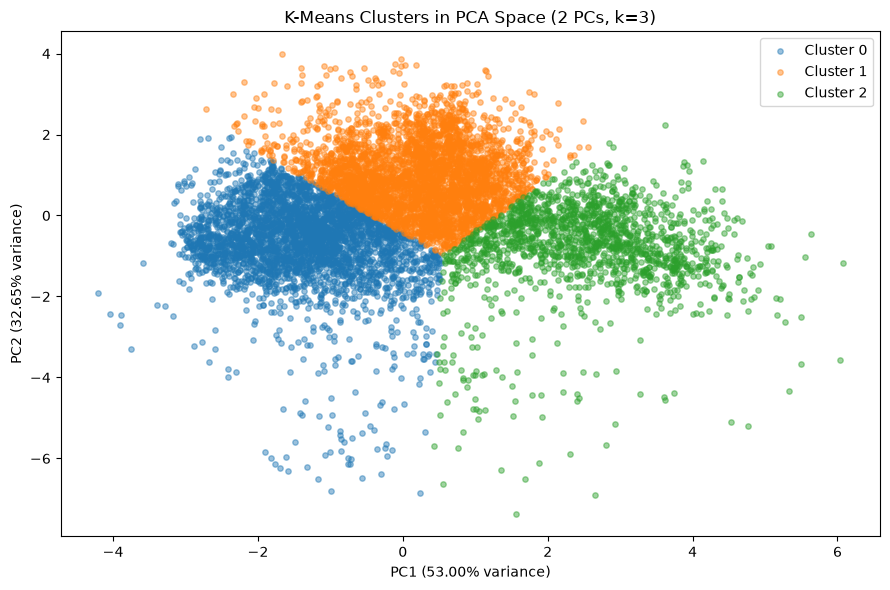

In [64]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster_id in sorted(clustered_tours["cluster"].unique()):
    mask = clustered_tours["cluster"].to_numpy() == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.45,
        s=15
    )

plt.xlabel("PC1 (53.00% variance)")
plt.ylabel("PC2 (32.65% variance)")
plt.title("K-Means Clusters in PCA Space (2 PCs, k=3)")
plt.legend()
plt.tight_layout()
plt.show()


In [65]:

import pandas as pd

# Map each reconstructed tour to its vehicle and fleet identifier
tour_metadata = (
    reconstructed.groupby("reconstructed_tour_id")
    .agg(
        vehicle_id=("vehicle_id", "first"),
        fleet_test_id=("fleet_test_id", "first"),
    )
    .reset_index()
)

cluster_validation = clustered_tours[
    ["reconstructed_tour_id", "cluster"]
].merge(
    tour_metadata,
    on="reconstructed_tour_id",
    how="left",
    validate="one_to_one",
)

print("Missing vehicle IDs:", cluster_validation["vehicle_id"].isna().sum())

# Cluster distribution by fleet identifier
fleet_counts = pd.crosstab(
    cluster_validation["fleet_test_id"],
    cluster_validation["cluster"],
)

fleet_percentages = (
    pd.crosstab(
        cluster_validation["fleet_test_id"],
        cluster_validation["cluster"],
        normalize="index",
    ) * 100
)

print("Tour counts by fleet identifier:")
display(fleet_counts)

print("Within-fleet cluster percentages:")
display(fleet_percentages.round(1))

# How widely does each cluster occur across vehicles?
vehicle_cluster_counts = pd.crosstab(
    cluster_validation["vehicle_id"],
    cluster_validation["cluster"],
)

print("Number of vehicles represented in each cluster:")
display(
    (vehicle_cluster_counts > 0)
    .sum()
    .rename("vehicles_with_cluster")
    .to_frame()
)

print("Vehicles with the most tours in each cluster:")
display(
    vehicle_cluster_counts.sort_values(
        list(vehicle_cluster_counts.columns),
        ascending=False,
    ).head(15)
)


Missing vehicle IDs: 0
Tour counts by fleet identifier:


cluster,0,1,2
fleet_test_id,,,
1,839,610,286
2,278,411,31
3,962,433,90
4,96,218,495
5,992,1544,70
6,265,386,609


Within-fleet cluster percentages:


cluster,0,1,2
fleet_test_id,,,
1,48.4,35.2,16.5
2,38.6,57.1,4.3
3,64.8,29.2,6.1
4,11.9,26.9,61.2
5,38.1,59.2,2.7
6,21.0,30.6,48.3


Number of vehicles represented in each cluster:


,vehicles_with_cluster
cluster,
0,128
1,142
2,144


Vehicles with the most tours in each cluster:


cluster,0,1,2
vehicle_id,,,
62,253,2,11
63,230,16,10
31,220,5,9
32,195,3,2
59,184,374,4
7,125,33,1
54,121,328,11
61,111,132,5
4,101,30,3
